   # Alzheimer's Disease Classification and Clustering

   **IT326 Data Mining – Final Report**

   **Team:** Noura Alfaadhel, Wafa Alobaidi, Aljohara Aljeraisy, Joud Aldawsari, Sarah Alhamdan.

# [1] Problem

Alzheimer's disease is a progressive neurological condition that affects memory, thinking, and behavior. It affects more than 55 million people worldwide, and this number is expected to reach 138 million by 2050 [1]. The disease can significantly affect a person's independence and quality of life, and it places a growing burden on families and health systems.

Early detection is important because it gives patients and doctors more time to plan treatment and care. Doctors already record many routine measurements for each patient, such as cognitive test scores, the ability to perform daily activities, symptoms, medical history, and lifestyle habits. The problem we want to solve is: can these patient records be used to (1) predict whether a patient has Alzheimer's disease, and (2) find groups of patients who share similar characteristics? Answering these questions can help reveal which patient characteristics are most associated with the disease and support earlier screening.

# [2] Data Mining Task

We formalize the problem as two data mining tasks:

**1. Classification (supervised learning):** The goal is to predict the class attribute **Diagnosis** (0 = not diagnosed with Alzheimer's disease, 1 = diagnosed) from the patients' attributes. This is a binary classification task. We apply **Decision Tree** classifiers using two attribute selection measures, the **Gini index** and **Information Gain (entropy)**, on three train/test partitions (90/10, 80/20, and 70/30), and evaluate them using accuracy and confusion matrices.

**2. Clustering (unsupervised learning):** The goal is to group patients with similar characteristics **without using the Diagnosis label**. We apply **K-means** clustering with K = 2, 3, and 4, and evaluate the clusters using the Silhouette coefficient and the Elbow method (total within-cluster sum of squares). After clustering, we compare the clusters with the Diagnosis label to check whether the groups found are related to Alzheimer's disease.

# [3] Data


## 3.1 Dataset Source and Description
The dataset used in this project is the Alzheimer’s Disease Dataset, obtained from Kaggle [2].

Dataset URL: https://www.kaggle.com/datasets/rabieelkharoua/alzheimers-disease-dataset

The Alzheimer's Disease Dataset contains information about 2,149 patients and consists of 35 attributes. The attributes include demographic, lifestyle, medical, clinical, cognitive, and functional information. The class attribute is Diagnosis, which indicates whether a patient has Alzheimer's disease.


In [302]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/Wafa-Alobaidi/IT326-Data-Mining-Project/refs/heads/main/Dataset/Raw_dataset.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [303]:
print("Number of rows:", df.shape[0])
print("Number of attributes:", df.shape[1])

Number of rows: 2149
Number of attributes: 35


In [304]:
print(df.dtypes)

PatientID                      int64
Age                            int64
Gender                         int64
Ethnicity                      int64
EducationLevel                 int64
BMI                          float64
Smoking                        int64
AlcoholConsumption           float64
PhysicalActivity             float64
DietQuality                  float64
SleepQuality                 float64
FamilyHistoryAlzheimers        int64
CardiovascularDisease          int64
Diabetes                       int64
Depression                     int64
HeadInjury                     int64
Hypertension                   int64
SystolicBP                     int64
DiastolicBP                    int64
CholesterolTotal             float64
CholesterolLDL               float64
CholesterolHDL               float64
CholesterolTriglycerides     float64
MMSE                         float64
FunctionalAssessment         float64
MemoryComplaints               int64
BehavioralProblems             int64
A

In [305]:
print("Class attribute: Diagnosis")
print("Class values:", df["Diagnosis"].unique())

Class attribute: Diagnosis
Class values: [0 1]


In [306]:
print("Number of instances for each class:")
print(df["Diagnosis"].value_counts())

Number of instances for each class:
Diagnosis
0    1389
1     760
Name: count, dtype: int64


In [307]:
print("Sample of Raw Dataset (First 5 Rows):")
df.head()

Sample of Raw Dataset (First 5 Rows):


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


## 3.2 Statistical Summary and Missing Values

In [308]:
import pandas as pd
import numpy as np

df = pd.read_csv('https://raw.githubusercontent.com/Wafa-Alobaidi/IT326-Data-Mining-Project/refs/heads/main/Dataset/Raw_dataset.csv')

print("Shape:", df.shape)
df.info()

Shape: (2149, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2149 entries, 0 to 2148
Data columns (total 35 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PatientID                  2149 non-null   int64  
 1   Age                        2149 non-null   int64  
 2   Gender                     2149 non-null   int64  
 3   Ethnicity                  2149 non-null   int64  
 4   EducationLevel             2149 non-null   int64  
 5   BMI                        2149 non-null   float64
 6   Smoking                    2149 non-null   int64  
 7   AlcoholConsumption         2149 non-null   float64
 8   PhysicalActivity           2149 non-null   float64
 9   DietQuality                2149 non-null   float64
 10  SleepQuality               2149 non-null   float64
 11  FamilyHistoryAlzheimers    2149 non-null   int64  
 12  CardiovascularDisease      2149 non-null   int64  
 13  Diabetes                   214

In [309]:
id_cols = ['PatientID', 'DoctorInCharge']

categorical_cols = [
    'Gender', 'Ethnicity', 'EducationLevel', 'Smoking',
    'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'Depression',
    'HeadInjury', 'Hypertension', 'MemoryComplaints', 'BehavioralProblems',
    'Confusion', 'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks',
    'Forgetfulness', 'Diagnosis'
]

numeric_cols = [
    'Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality',
    'SleepQuality', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal',
    'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides',
    'MMSE', 'FunctionalAssessment', 'ADL'
]

# sanity check — run this and confirm it prints an empty set
leftover = set(df.columns) - set(id_cols + categorical_cols + numeric_cols)
print("Unclassified columns:", leftover)

Unclassified columns: set()


In [310]:
# Numeric summary
print(df[numeric_cols].describe())

# Categorical summary
for col in categorical_cols:
    print(f"\n{col} value counts:")
    print(df[col].value_counts())

               Age          BMI  AlcoholConsumption  PhysicalActivity  \
count  2149.000000  2149.000000         2149.000000       2149.000000   
mean     74.908795    27.655697           10.039442          4.920202   
std       8.990221     7.217438            5.757910          2.857191   
min      60.000000    15.008851            0.002003          0.003616   
25%      67.000000    21.611408            5.139810          2.570626   
50%      75.000000    27.823924            9.934412          4.766424   
75%      83.000000    33.869778           15.157931          7.427899   
max      90.000000    39.992767           19.989293          9.987429   

       DietQuality  SleepQuality   SystolicBP  DiastolicBP  CholesterolTotal  \
count  2149.000000   2149.000000  2149.000000  2149.000000       2149.000000   
mean      4.993138      7.051081   134.264774    89.847836        225.197519   
std       2.909055      1.763573    25.949352    17.592496         42.542233   
min       0.009385    

In [311]:
five_number = df[numeric_cols].describe().loc[['min', '25%', '50%', '75%', 'max']]
print(five_number)

      Age        BMI  AlcoholConsumption  PhysicalActivity  DietQuality  \
min  60.0  15.008851            0.002003          0.003616     0.009385   
25%  67.0  21.611408            5.139810          2.570626     2.458455   
50%  75.0  27.823924            9.934412          4.766424     5.076087   
75%  83.0  33.869778           15.157931          7.427899     7.558625   
max  90.0  39.992767           19.989293          9.987429     9.998346   

     SleepQuality  SystolicBP  DiastolicBP  CholesterolTotal  CholesterolLDL  \
min      4.002629        90.0         60.0        150.093316       50.230707   
25%      5.482997       112.0         74.0        190.252963       87.195798   
50%      7.115646       134.0         91.0        225.086430      123.342593   
75%      8.562521       157.0        105.0        262.031657      161.733733   
max      9.999840       179.0        119.0        299.993352      199.965665   

     CholesterolHDL  CholesterolTriglycerides       MMSE  \
min     

In [312]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_summary = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print(missing_summary[missing_summary['Missing Count'] > 0])

# If nothing prints, explicitly state it:
if missing.sum() == 0:
    print("No missing values found in the dataset.")

Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []
No missing values found in the dataset.


### Interpretation

- **Dataset shape:** The dataset contains 2,149 patients and 35 attributes — 18 categorical/binary variables (including the class label `Diagnosis`), 15 numeric/continuous variables, and 2 identifier columns excluded from analysis.

- **Five-number summary insights:** All 15 numeric attributes fall within plausible clinical and lifestyle ranges (e.g., Age 60–90, SystolicBP 90–179, CholesterolTotal 150–300), with no impossible or extreme values in the min/max. Distributions appear roughly uniform across their ranges rather than skewed, which is examined further in the outlier analysis (Section 3.3).

- **Missing values:** No missing values were found in any of the 35 columns, confirmed by both the missing-value check and the non-null counts in `df.info()`. This is consistent with Dubey et al. [1], who used the full dataset of 2,149 patients. No preprocessing is required for missingness specifically.

- **Excluded columns:** `PatientID` was excluded from statistical interpretation as it is only a unique identifier with no analytical meaning. `DoctorInCharge` was excluded/treated separately, as it holds the same (confidential) value for all patients and is not a useful feature.

- **Overall preprocessing recommendation (from this section only):** No missing-value handling is needed. Whether other preprocessing steps (scaling, outlier treatment, encoding) are needed is evaluated in the following sections.

## 3.3 Outlier Detection and Boxplot Analysis

In [313]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Strictly genuine continuous numeric features per team agreement
continuous_cols = [
    'Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity',
    'DietQuality', 'SleepQuality', 'SystolicBP', 'DiastolicBP',
    'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
    'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment', 'ADL'
]

# Calculate IQR bounds and outlier counts
outlier_summary = []
for col in continuous_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]
    outlier_summary.append({
        'Feature': col,
        'Min': round(df[col].min(), 2),
        'Q1 (25%)': round(q1, 2),
        'Median (50%)': round(df[col].median(), 2),
        'Q3 (75%)': round(q3, 2),
        'Max': round(df[col].max(), 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier %': round((len(outliers) / len(df)) * 100, 2)
    })

outlier_table = pd.DataFrame(outlier_summary)
print("=== Outlier Detection via IQR Method ===")
display(outlier_table)

=== Outlier Detection via IQR Method ===


,Feature,Min,Q1 (25%),Median (50%),Q3 (75%),Max,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Age,60.00,67.00,75.00,83.00,90.00,43.00,107.00,0,0.0
1,BMI,15.01,21.61,27.82,33.87,39.99,3.22,52.26,0,0.0
2,AlcoholConsumption,0.00,5.14,9.93,15.16,19.99,-9.89,30.19,0,0.0
3,PhysicalActivity,0.00,2.57,4.77,7.43,9.99,-4.72,14.71,0,0.0
4,DietQuality,0.01,2.46,5.08,7.56,10.00,-5.19,15.21,0,0.0
5,SleepQuality,4.00,5.48,7.12,8.56,10.00,0.86,13.18,0,0.0
6,SystolicBP,90.00,112.00,134.00,157.00,179.00,44.50,224.50,0,0.0
7,DiastolicBP,60.00,74.00,91.00,105.00,119.00,27.50,151.50,0,0.0
8,CholesterolTotal,150.09,190.25,225.09,262.03,299.99,82.58,369.70,0,0.0
9,CholesterolLDL,50.23,87.20,123.34,161.73,199.97,-24.61,273.54,0,0.0


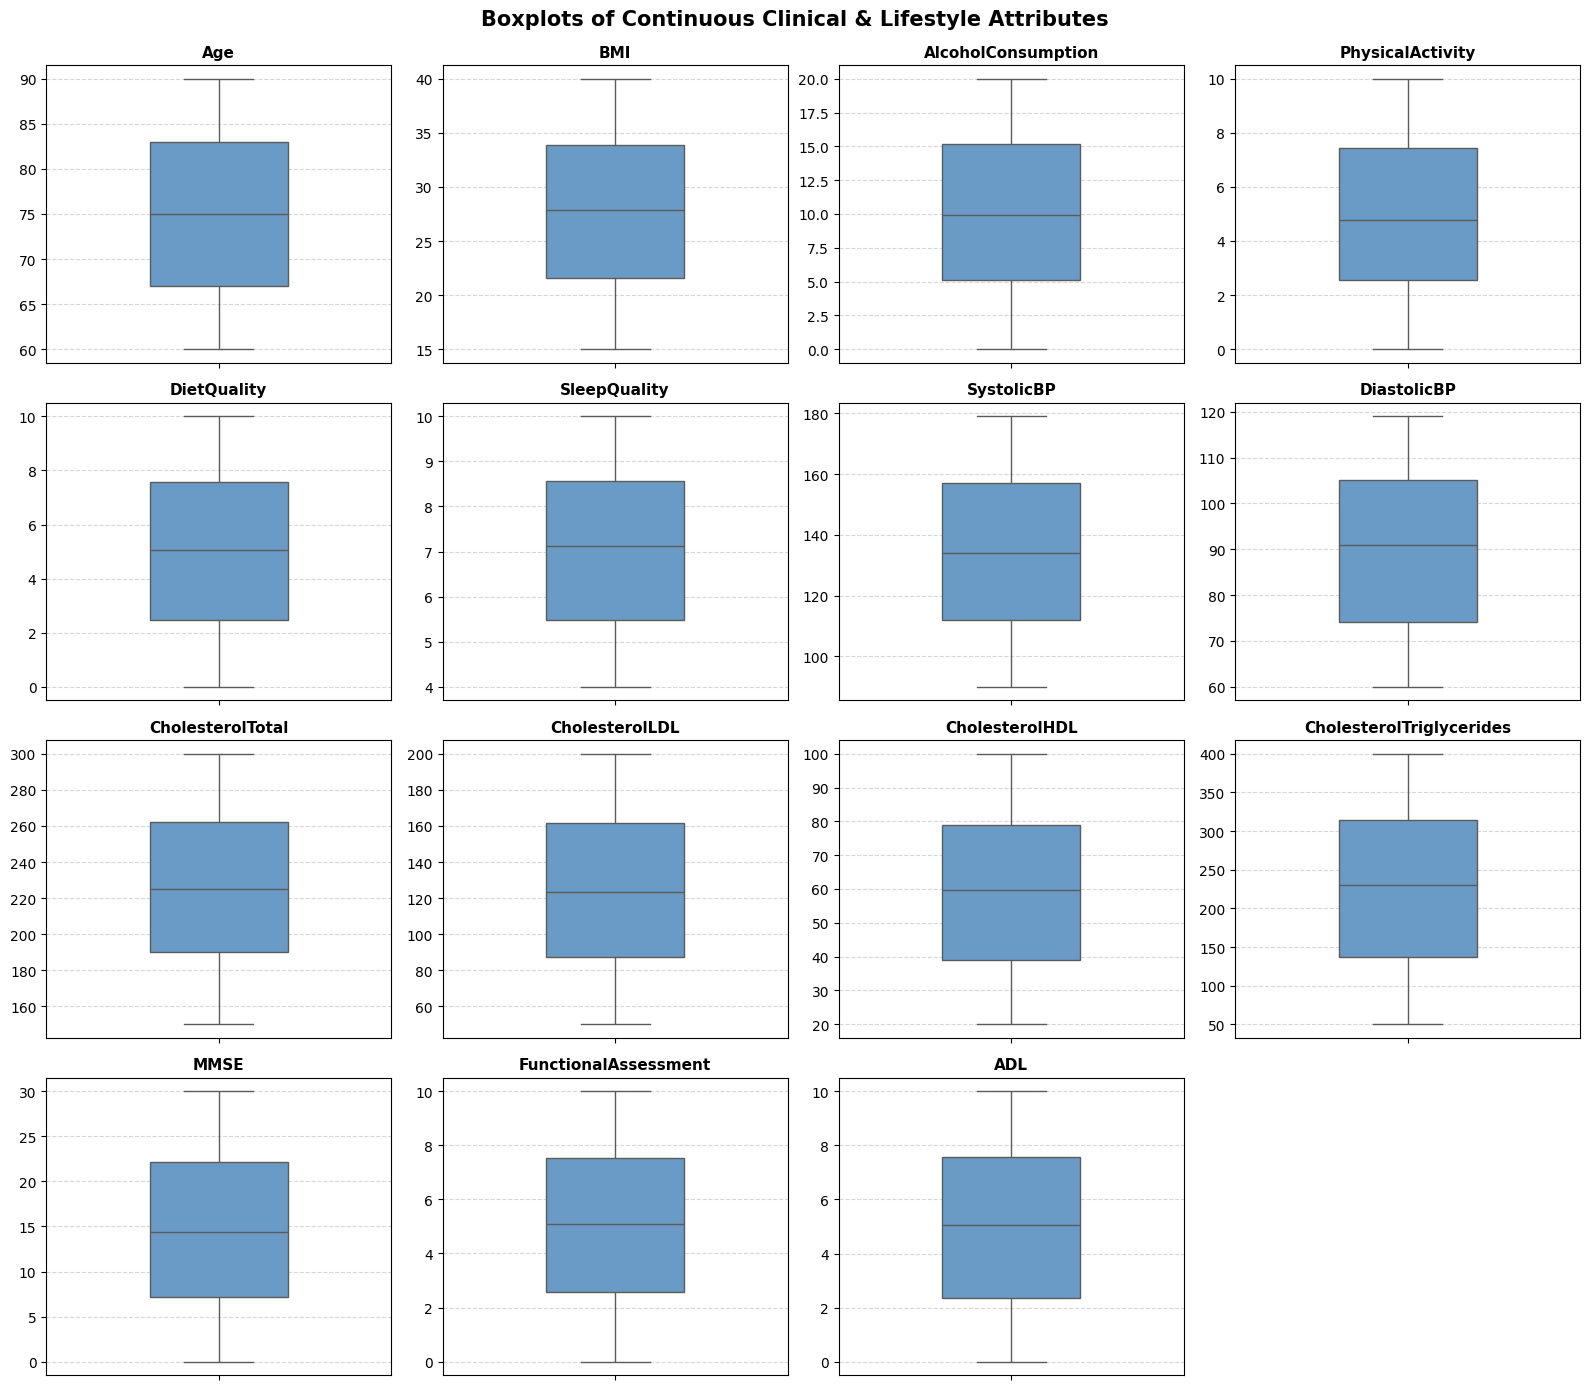

In [314]:
# Plotting boxplots for all continuous features
plt.figure(figsize=(16, 14))
for i, col in enumerate(continuous_cols, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(y=df[col], color='#5B9BD5', fliersize=4, width=0.4)
    plt.title(f'{col}', fontsize=11, fontweight='bold')
    plt.ylabel('')
    plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Boxplots of Continuous Clinical & Lifestyle Attributes", fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

### Interpretation

* **Scope of analysis:** Outlier detection and boxplot visualization were performed exclusively on the 15 continuous numeric variables (Age, BMI, AlcoholConsumption, PhysicalActivity, DietQuality, SleepQuality, SystolicBP, DiastolicBP, CholesterolTotal, CholesterolLDL, CholesterolHDL, CholesterolTriglycerides, MMSE, FunctionalAssessment, and ADL), excluding all 18 categorical/binary variables as well as PatientID and DoctorInCharge.

* **Boxplot visual observations:** The boxplots show balanced and symmetric distributions across the 15 continuous attributes. Medians are positioned near the center of the interquartile boxes, and the whiskers span the entire observed range from minimum to maximum without isolated points extending beyond the bounds (outliers).

* **Outlier detection results:** Using the standard $1.5 \times IQR$ rule ($[\text{Lower Bound} = Q_1 - 1.5 \times IQR, \text{Upper Bound} = Q_3 + 1.5 \times IQR]$), zero outliers (0 instances, 0.0%) were detected in any of the 15 attributes. All minimum and maximum values fall strictly within their respective calculated lower and upper thresholds.

* **Overall preprocessing recommendation (from this section):** No outlier treatment (such as trimming, removal, or Winsorization/capping) is required or justified, as modifying valid clinical records would distort natural variations.

## 3.4 Distributions and Class Analysis

### 3.4.1 Numerical Attribute Distributions

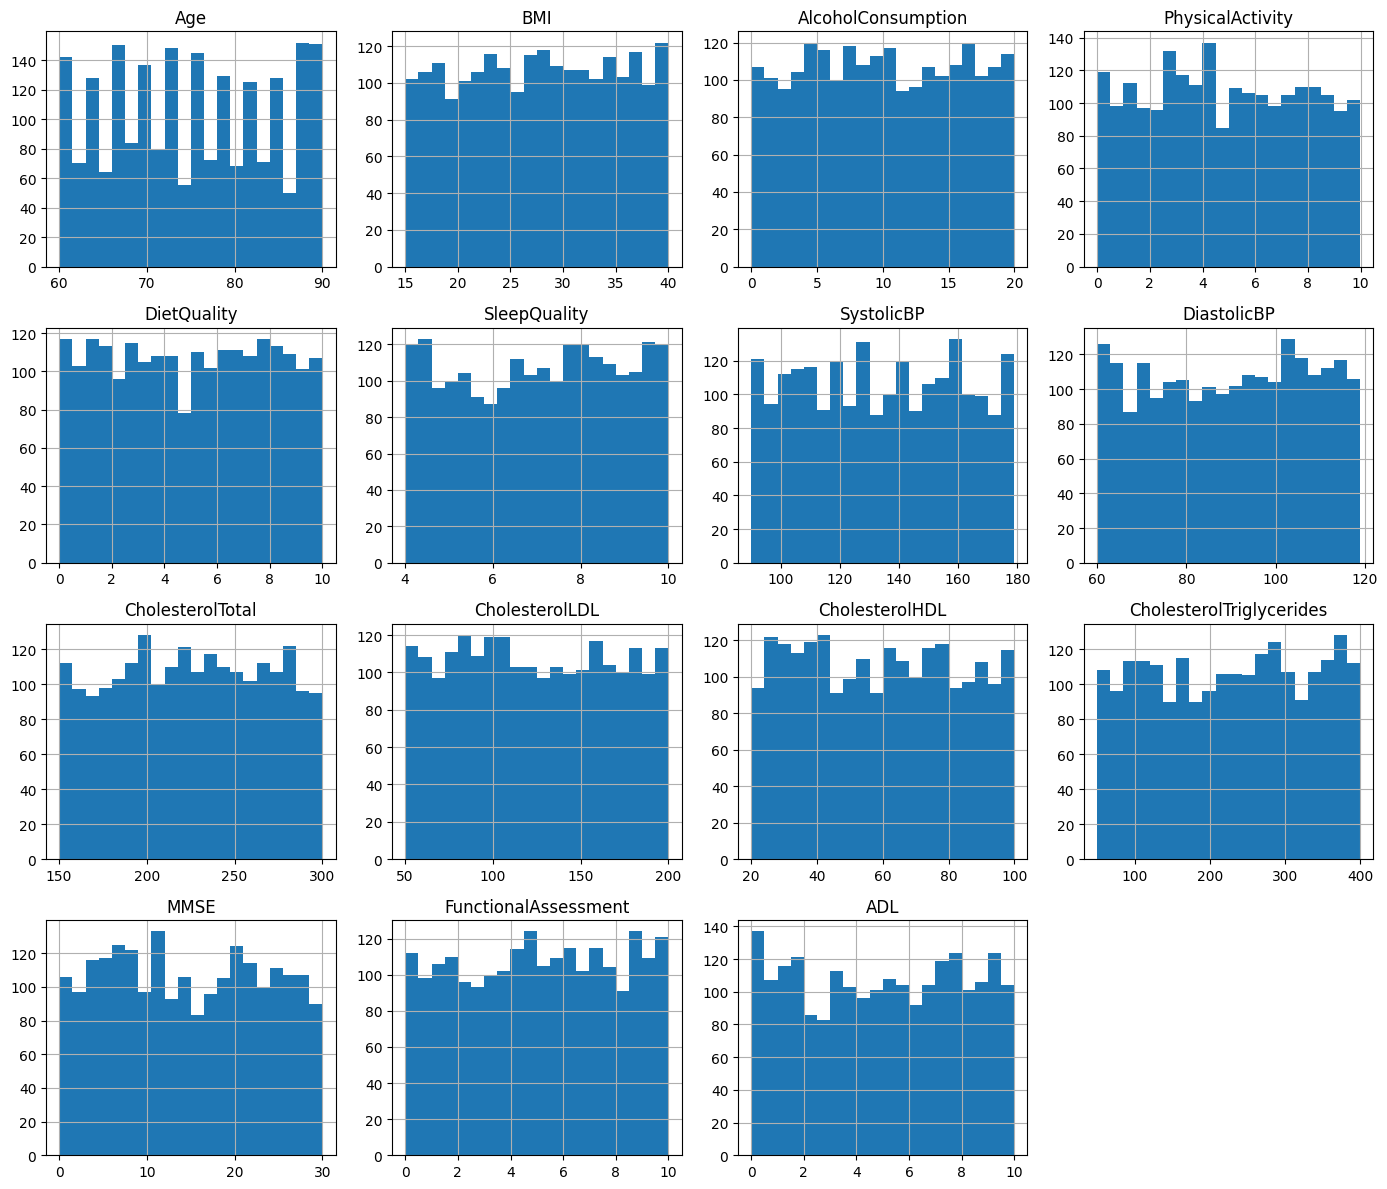

In [315]:
numerical_attributes = [
    'Age',
    'BMI',
    'AlcoholConsumption',
    'PhysicalActivity',
    'DietQuality',
    'SleepQuality',
    'SystolicBP',
    'DiastolicBP',
    'CholesterolTotal',
    'CholesterolLDL',
    'CholesterolHDL',
    'CholesterolTriglycerides',
    'MMSE',
    'FunctionalAssessment',
    'ADL'
]

df[numerical_attributes].hist(figsize=(14, 12), bins=20)
plt.tight_layout()
plt.show()

The histograms show the distributions of the 15 numerical attributes. All of them are approximately uniform across their ranges, with no strong skewness, so no variable transformation is needed. However, the attributes are measured on very different scales (for example, Age ranges from 60 to 90, while CholesterolTriglycerides ranges from 50 to 400), so Min-Max normalization was applied in Section 4.1 to make them comparable. The BMI histogram also shows values spread across all clinical weight ranges (15 to 40), which supports discretizing it into WHO categories (Section 4.2). The comb-like pattern in the Age histogram is a binning effect: Age is a whole number with 31 possible values spread over 20 bins, so some bins hold two ages and others hold one.


### 3.4.2 Categorical Attribute Distributions

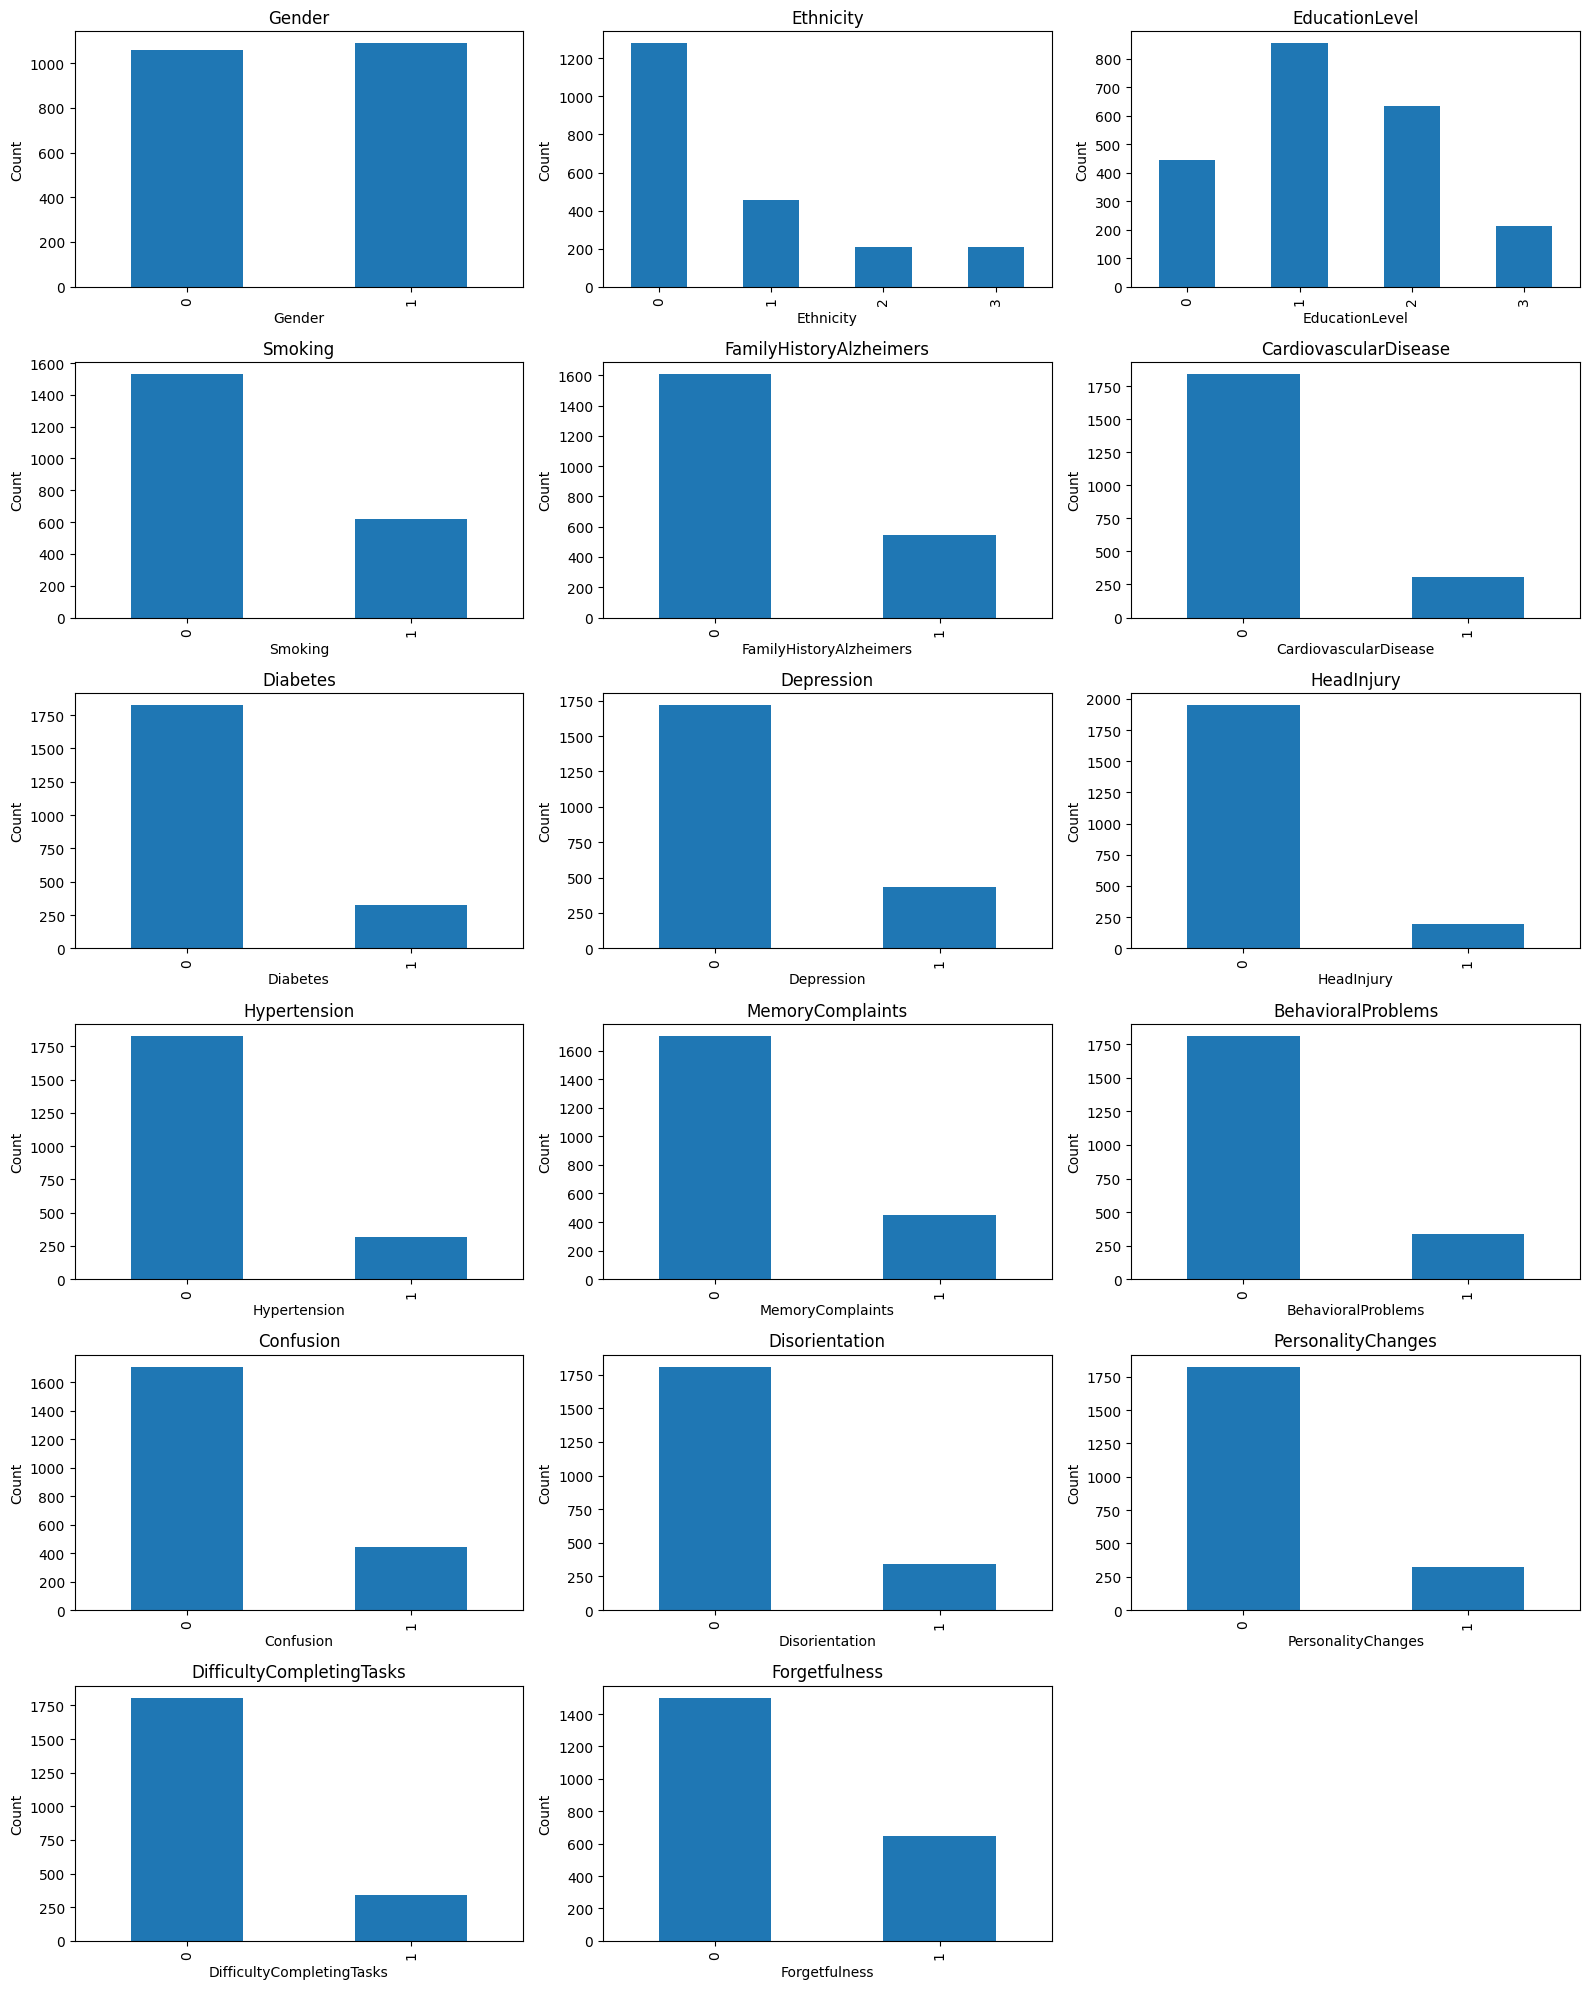

In [316]:
categorical_attributes = [
    'Gender', 'Ethnicity', 'EducationLevel', 'Smoking', 'FamilyHistoryAlzheimers',
    'CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury', 'Hypertension',
    'MemoryComplaints', 'BehavioralProblems', 'Confusion', 'Disorientation',
    'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness'
]

fig, axes = plt.subplots(6, 3, figsize=(16, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_attributes):
    df[col].value_counts().sort_index().plot(
        kind='bar',
        ax=axes[i],
        title=col,
    )
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

for j in range(len(categorical_attributes), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

The bar plots show the frequency distribution of the 17 categorical attributes. Gender is nearly balanced (1,088 vs. 1,061). Ethnicity is dominated by group 0 (1,278 patients, 59.5%), and EducationLevel is most often level 1 (854 patients, 39.7%). The binary medical history and symptom attributes are all skewed toward 0 (absent): for example, only 199 patients (9.3%) have a head injury and 310 (14.4%) have cardiovascular disease, while Forgetfulness is the most common symptom (648 patients, 30.2%). These imbalances reflect realistic prevalence rates and are not errors, so no correction was applied. All categorical attributes are already numerically encoded (binary 0/1 or integer category codes), so no encoding step is needed.


### 3.4.3 Class Label Distribution

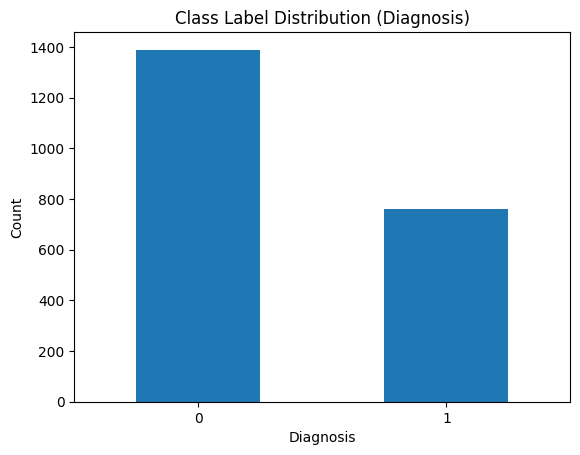

Diagnosis
0    1389
1     760
Name: count, dtype: int64


In [317]:
diagnosis_counts = df['Diagnosis'].value_counts().sort_index()

diagnosis_counts.plot(kind='bar')

plt.xlabel('Diagnosis')
plt.ylabel('Count')
plt.title('Class Label Distribution (Diagnosis)')
plt.xticks(rotation=0)
plt.show()

print(diagnosis_counts)


**Interpretation:** The class label is binary: 1,389 patients (64.6%) are not diagnosed with Alzheimer's (0) and 760 (35.4%) are diagnosed (1). This is a moderate class imbalance. It does not require resampling in preprocessing, but in Phase 3 we will use a stratified train/test split so both classes keep the same proportions in each partition.


## 3.5 Relationship Analysis

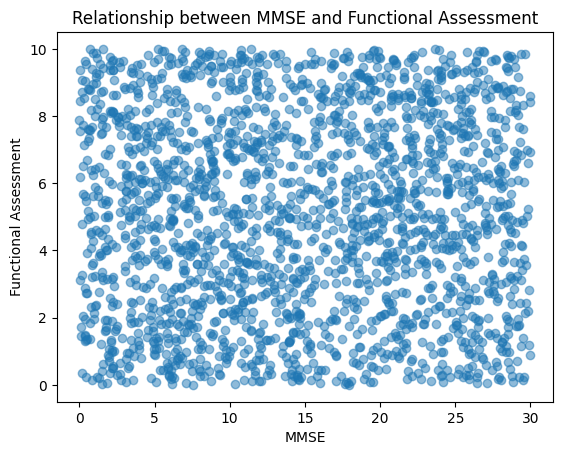

In [318]:
import matplotlib.pyplot as plt

plt.scatter(df['MMSE'], df['FunctionalAssessment'], alpha=0.5)

plt.xlabel('MMSE')
plt.ylabel('Functional Assessment')
plt.title('Relationship between MMSE and Functional Assessment')

plt.show()

**Interpretation:**
The scatter plot shows no clear linear relationship between MMSE and Functional Assessment. The points are widely scattered, indicating that changes in MMSE are not strongly associated with consistent changes in Functional Assessment. This result did not indicate a need for transformation based on the relationship between these two attributes.

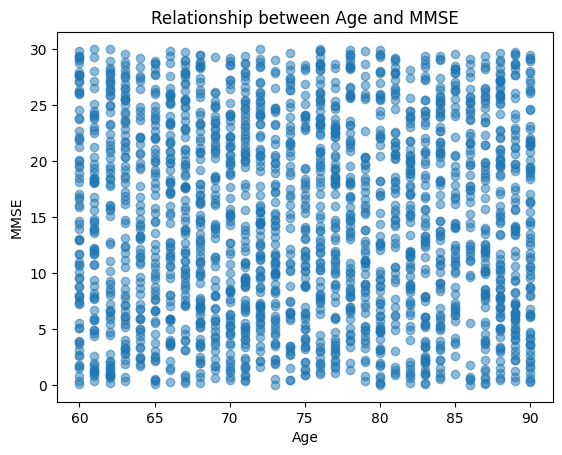

In [319]:
plt.scatter(df['Age'], df['MMSE'], alpha=0.5)

plt.xlabel('Age')
plt.ylabel('MMSE')
plt.title('Relationship between Age and MMSE')

plt.show()

**Interpretation:**
The scatter plot shows no clear linear relationship between Age and MMSE. MMSE scores are widely distributed across all age groups, indicating that age alone does not show a strong association with MMSE scores in this dataset. This result also did not indicate a need for transformation based on the relationship between these two attributes.

# [4] Data Preprocessing

## 4.1 Normalization

**Preprocessing Decision:** The analysis showed no missing values, no outliers, and no strong skewness, so missing-value treatment, outlier treatment, and transformation were not required. Three preprocessing techniques were applied: (1) Min-Max normalization of the continuous attributes because they are measured on different scales; (2) discretization of BMI into four clinical categories (Underweight, Normal, Overweight, and Obese); and (3) feature selection using Mutual Information with the class label (Section 4.3). The original raw dataset was kept unchanged.

In [320]:
from sklearn.preprocessing import MinMaxScaler

numerical_columns = [
    'Age', 'BMI', 'AlcoholConsumption', 'PhysicalActivity',
    'DietQuality', 'SleepQuality', 'SystolicBP', 'DiastolicBP',
    'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
    'CholesterolTriglycerides', 'MMSE',
    'FunctionalAssessment', 'ADL'
]

df_normalized = df.copy()

scaler = MinMaxScaler()
df_normalized[numerical_columns] = scaler.fit_transform(
    df_normalized[numerical_columns]
)

In [321]:
df_normalized[numerical_columns].agg(['min', 'max'])

,Age,BMI,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,SystolicBP,DiastolicBP,CholesterolTotal,CholesterolLDL,CholesterolHDL,CholesterolTriglycerides,MMSE,FunctionalAssessment,ADL
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Normalization Result:**
Min-Max normalization was successfully applied to the 15 continuous numerical attributes. After normalization, the minimum value of each attribute is 0 and the maximum value is 1. The categorical/binary attributes and the class label (Diagnosis) were not normalized.



## 4.2 Discretization

**Discretization Decision:** BMI is a continuous numerical attribute. It was discretized into four categories: Underweight (<18.5), Normal (18.5–24.9), Overweight (25–29.9), and Obese (≥30). This converts the continuous BMI values into clinically meaningful groups while keeping the original raw dataset unchanged.

In [322]:
bmi_bins = [0, 18.5, 25, 30, float('inf')]
bmi_labels = [0, 1, 2, 3]

df_normalized['BMI_Category'] = pd.cut(
    df['BMI'],
    bins=bmi_bins,
    labels=bmi_labels,
    right=False
).astype(int)

# Remove the original continuous BMI attribute
df_normalized = df_normalized.drop(columns=['BMI'])

df_normalized['BMI_Category'].value_counts().sort_index()

,count
BMI_Category,
0,297
1,544
2,437
3,871


**Discretization Result:** BMI was successfully discretized into four categories: Underweight = 297, Normal = 544, Overweight = 437, and Obese = 871 patients. The continuous BMI attribute was replaced by the new BMI_Category attribute to represent clinically meaningful BMI groups.

## 4.3 Feature Selection

Feature selection was performed in two steps. First, PatientID and DoctorInCharge were removed because they are identifiers with no analytical value. Second, mutual information (MI) was calculated between each remaining attribute and Diagnosis to measure how much information each attribute provides about the class. Attributes with near-zero MI were removed, because irrelevant attributes add noise and especially harm K-means clustering, where every attribute contributes to the distance calculation.

FunctionalAssessment         9.545358e-02
ADL                          7.656440e-02
MMSE                         6.627780e-02
MemoryComplaints             4.525652e-02
BehavioralProblems           2.404733e-02
AlcoholConsumption           1.778024e-02
CholesterolHDL               1.734934e-02
SleepQuality                 9.691288e-03
PhysicalActivity             7.946601e-03
Age                          6.752936e-03
SystolicBP                   6.447558e-03
Ethnicity                    1.465159e-03
BMI_Category                 1.182164e-03
EducationLevel               1.034077e-03
Hypertension                 6.074235e-04
FamilyHistoryAlzheimers      5.456632e-04
Diabetes                     5.031651e-04
CardiovascularDisease        4.899146e-04
CholesterolTotal             3.381637e-04
Disorientation               3.068256e-04
HeadInjury                   2.322640e-04
Gender                       2.199678e-04
PersonalityChanges           2.145972e-04
Confusion                    1.851

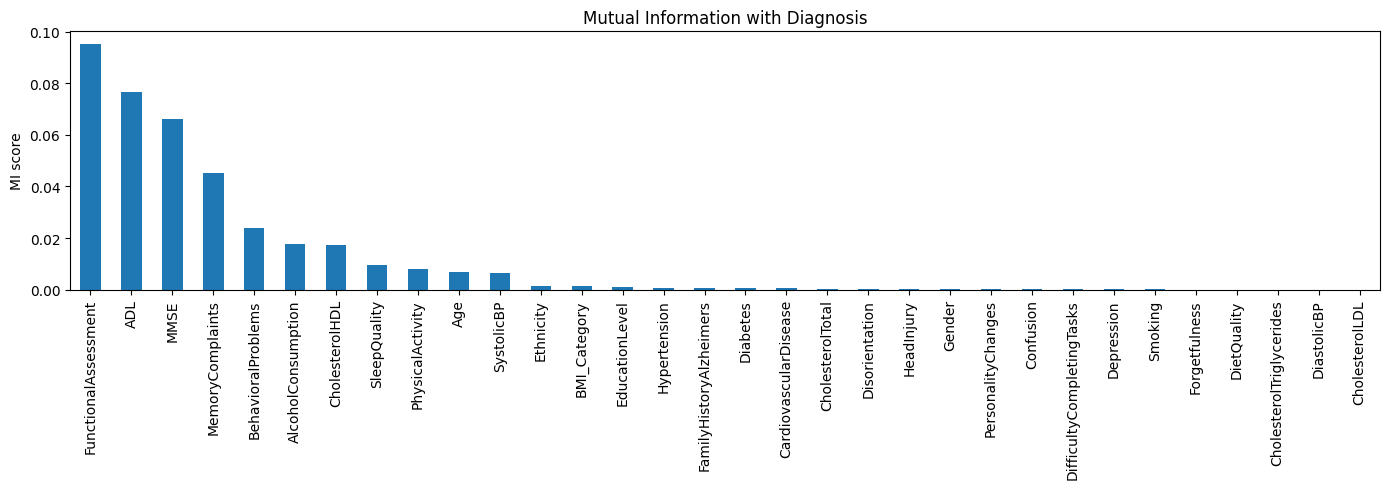

In [323]:
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
df_final = df_normalized.drop(columns=['PatientID', 'DoctorInCharge'])
X = df_final.drop(columns=['Diagnosis'])
y = df_final['Diagnosis']
discrete_mask = [col not in numerical_columns for col in X.columns]
mi = pd.Series(mutual_info_classif(X, y, discrete_features=discrete_mask, random_state=42),
               index=X.columns).sort_values(ascending=False)
print(mi)
mi.plot(kind='bar', figsize=(14, 5), title='Mutual Information with Diagnosis')
plt.ylabel('MI score')
plt.tight_layout()
plt.show()

In [324]:
threshold = 0.01

selected = mi[mi > threshold].index.tolist()

df_final = df_final[selected + ['Diagnosis']]

print("Selected features:", selected)
print("Number of selected features:", len(selected))
print("Number of removed features:", len(mi) - len(selected))
print("Shape after feature selection:", df_final.shape)

Selected features: ['FunctionalAssessment', 'ADL', 'MMSE', 'MemoryComplaints', 'BehavioralProblems', 'AlcoholConsumption', 'CholesterolHDL']
Number of selected features: 7
Number of removed features: 25
Shape after feature selection: (2149, 8)


Feature Selection Result: The MI scores show that FunctionalAssessment, ADL, MMSE, and MemoryComplaints provide the most information about Diagnosis, while most other attributes scored close to zero. Using a threshold of 0.01, 7 attributes were kept and 25 were removed. The selected features are FunctionalAssessment, ADL, MMSE, MemoryComplaints, BehavioralProblems, AlcoholConsumption, and CholesterolHDL. BMI_Category was also removed at this step because its MI score was very low (≈0.001). This agrees with Dubey et al.[1], who used the K-Best method (Chi-square and ANOVA F-value) and selected FunctionalAssessment, MMSE, ADL, MemoryComplaints, and BehavioralProblems as the top 5 features; all five are included in our selection. Our selection also kept AlcoholConsumption and CholesterolHDL, which passed the threshold with lower MI scores. The final dataset has 8 attributes, including the class label.

## 4.4 Final Preprocessed Dataset

In [325]:
# Display the first five rows of the final preprocessed dataset
df_final.head()

,FunctionalAssessment,ADL,MMSE,MemoryComplaints,BehavioralProblems,AlcoholConsumption,CholesterolHDL,Diagnosis
0,0.652102,0.172486,0.715606,0,0,0.665183,0.171039,0
1,0.712108,0.259154,0.687251,0,0,0.227170,0.738026,0
2,0.589697,0.711936,0.245145,0,0,0.978276,0.622290,0
3,0.896823,0.648094,0.466410,0,1,0.610751,0.605851,0
4,0.604699,0.001341,0.450619,0,0,0.923204,0.461019,0


## 4.5 Raw vs. Preprocessed Dataset Comparison

In [326]:
# Compare the raw dataset with the final preprocessed dataset
print("Raw dataset shape:", df.shape)
print("Final preprocessed dataset shape:", df_final.shape)

print("\nRaw dataset columns:")
print(df.columns.tolist())

print("\nFinal preprocessed dataset columns:")
print(df_final.columns.tolist())

Raw dataset shape: (2149, 35)
Final preprocessed dataset shape: (2149, 8)

Raw dataset columns:
['PatientID', 'Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI', 'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality', 'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease', 'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP', 'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL', 'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment', 'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion', 'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks', 'Forgetfulness', 'Diagnosis', 'DoctorInCharge']

Final preprocessed dataset columns:
['FunctionalAssessment', 'ADL', 'MMSE', 'MemoryComplaints', 'BehavioralProblems', 'AlcoholConsumption', 'CholesterolHDL', 'Diagnosis']


In [327]:
# Snapshot of the raw dataset (unchanged)
df.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1,0,0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0,1,0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1,0,0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0,0,0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1,0,0,XXXConfid


In [328]:
# Compare sample values before and after preprocessing
comparison = pd.DataFrame({
    'Raw Age': df['Age'].head(),
    'Normalized Age': df_normalized['Age'].head(),
    'Raw BMI': df['BMI'].head(),
    'BMI Category': df_normalized['BMI_Category'].head()
})

comparison

,Raw Age,Normalized Age,Raw BMI,BMI Category
0,73,0.433333,22.927749,1
1,89,0.966667,26.827681,2
2,73,0.433333,17.795882,0
3,74,0.466667,33.800817,3
4,89,0.966667,20.716974,1


Comparison Result: The raw and preprocessed datasets contain the same 2,149 records, so no patients were removed. The number of attributes was reduced from 35 to 8 by removing the identifier columns and the low-information attributes found by feature selection. The continuous attributes were scaled to [0, 1] with Min-Max normalization, and the binary attributes and the Diagnosis label kept their original coded values. BMI was discretized into a 4-level clinical category (Section 4.2), but this category was later removed, but this category was later removed by feature selection due to its low MI score.

## 4.6 Save and Verify the Final Dataset

In [329]:
# Save the final preprocessed dataset
df_final.to_csv('Preprocessed_dataset.csv', index=False)

print("Preprocessed_dataset.csv saved successfully.")

Preprocessed_dataset.csv saved successfully.


In [330]:
# Verify the saved preprocessed dataset
df_check = pd.read_csv('Preprocessed_dataset.csv')

print("Saved dataset shape:", df_check.shape)
df_check.head()

Saved dataset shape: (2149, 8)


,FunctionalAssessment,ADL,MMSE,MemoryComplaints,BehavioralProblems,AlcoholConsumption,CholesterolHDL,Diagnosis
0,0.652102,0.172486,0.715606,0,0,0.665183,0.171039,0
1,0.712108,0.259154,0.687251,0,0,0.227170,0.738026,0
2,0.589697,0.711936,0.245145,0,0,0.978276,0.622290,0
3,0.896823,0.648094,0.466410,0,1,0.610751,0.605851,0
4,0.604699,0.001341,0.450619,0,0,0.923204,0.461019,0


# [5] Data Mining Technique

Both techniques are applied to the final preprocessed dataset from Phase 2 (`Preprocessed_dataset.csv`: 2,149 records, the 7 selected features, and the Diagnosis label). The team agreed on fixed settings so the results are reproducible and can be compared fairly.

## 5.1 Classification: Decision Tree
**Why:** A decision tree learns a set of if-then rules from the data. The rules can be drawn and read, so a doctor can see *why* a patient was classified as having Alzheimer's disease or not, which is important for medical data. Decision trees also do not need any further scaling of the features.

**How (Python packages and methods):**
- `sklearn.model_selection.train_test_split(X, y, test_size=..., random_state=42, stratify=y)` splits the data into **90/10, 80/20, and 70/30** train/test partitions. `stratify=y` keeps the same class proportions (about 65% / 35%) in the training and testing sets, because the classes are imbalanced (Section 3.4.3).
- `sklearn.tree.DecisionTreeClassifier(criterion="gini", random_state=42)` chooses each split using the **Gini index** [3].
- `sklearn.tree.DecisionTreeClassifier(criterion="entropy", random_state=42)` chooses each split using **Information Gain** (entropy) [4].
- All other settings are the scikit-learn defaults [5], so the only difference between the two models is the attribute selection measure.
- `sklearn.metrics.accuracy_score` and `confusion_matrix` evaluate each model on its test set, and `sklearn.tree.plot_tree` draws the tree.

This gives **6 configurations** (2 measures × 3 partitions).

## 5.2 Clustering: K-means
**Why:** K-means divides the patients into K groups so that patients in the same group are as similar as possible [6]. It is simple, fast, and its cluster centers (average feature values) are easy to interpret. It lets us check whether natural patient groups exist, without giving the algorithm the Diagnosis label.

**How (Python packages and methods):**
- The **Diagnosis** column is removed, so clustering uses only the 7 selected features.
- `sklearn.preprocessing.StandardScaler()` standardizes each feature (mean 0, standard deviation 1), because K-means uses Euclidean distance and every feature should contribute on the same scale.
- `sklearn.cluster.KMeans(n_clusters=K, random_state=42, n_init=10)` is run for **K = 2, 3, and 4**. `n_init=10` runs the algorithm 10 times from different starting points and keeps the best result.
- `sklearn.metrics.silhouette_score` computes the **average Silhouette width** [7], and `KMeans.inertia_` gives the **total within-cluster sum of squares (WCSS)** for the **Elbow method**.
- `sklearn.decomposition.PCA(n_components=2)` reduces the data to 2 dimensions **only to draw** the clusters; the clustering itself uses all 7 features.

# [6] Evaluation and Comparison

## 6.1 Classification: Decision Tree with Gini Index

In this section, we apply **Decision Tree classification** using the Gini Index attribute selection measure (criterion='gini').

* **Input Data:** We load the finalized Preprocessed_dataset.csv from Phase 2, separating the selected features ($X$) and the target variable (Diagnosis).
* **Partitions:** To evaluate model stability and generalization, we test three distinct train/test splits: **90/10**, **80/20**, and **70/30**.
* **Configuration Parameters:** We use random_state = 42 for complete reproducibility and stratify = y to maintain the natural class distribution across all splits. No further scaling is applied, as Decision Trees are invariant to monotonic feature scaling.


DECISION TREE CLASSIFICATION (GINI INDEX)

--- Partition: 90/10 Train/Test Split ---
Accuracy: 0.9209 (92.09%)
Confusion Matrix:
[[128  11]
 [  6  70]]

--- Partition: 80/20 Train/Test Split ---
Accuracy: 0.9140 (91.40%)
Confusion Matrix:
[[257  21]
 [ 16 136]]

--- Partition: 70/30 Train/Test Split ---
Accuracy: 0.8822 (88.22%)
Confusion Matrix:
[[380  37]
 [ 39 189]]


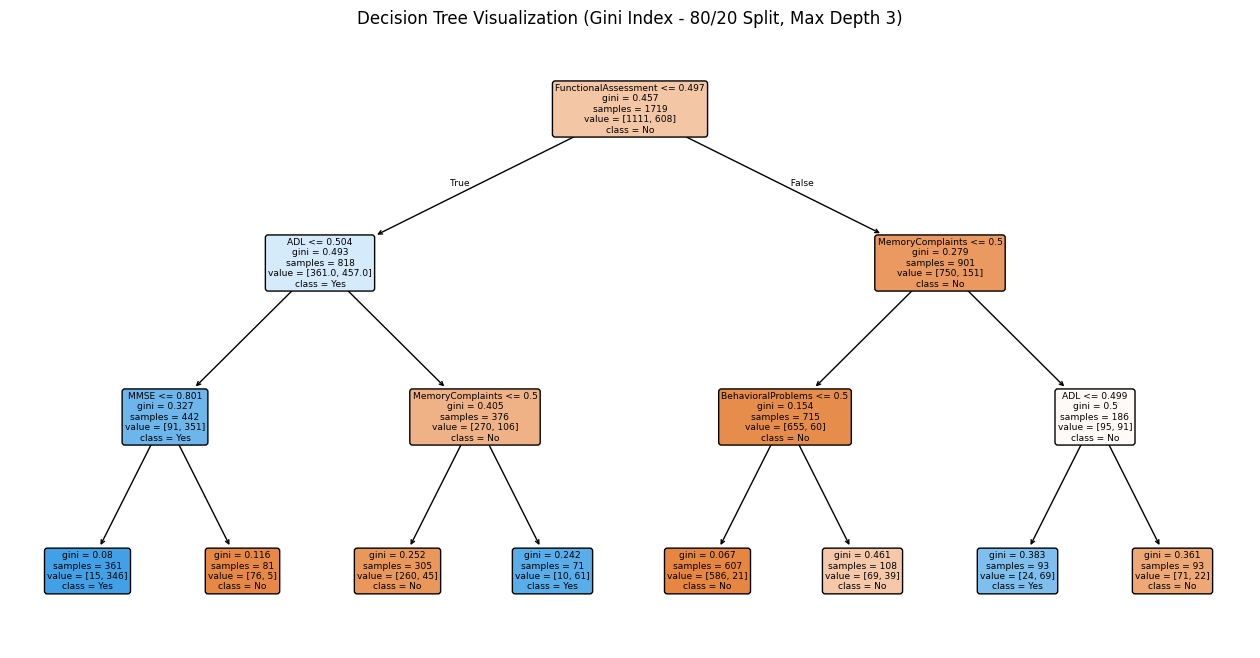

In [331]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt

# 1. Load the preprocessed dataset from Phase 2
df_preprocessed = pd.read_csv('Preprocessed_dataset.csv')

# 2. Define features (X) and target (y)
X = df_preprocessed.drop(columns=['Diagnosis'])
y = df_preprocessed['Diagnosis']

# 3. Define the three partition sizes required by project guidelines
splits = [
    {"train": 0.90, "test": 0.10, "name": "90/10"},
    {"train": 0.80, "test": 0.20, "name": "80/20"},
    {"train": 0.70, "test": 0.30, "name": "70/30"}
]

# Dictionary to store results for Student 4's comparison table
gini_results = {}

print()
print("DECISION TREE CLASSIFICATION (GINI INDEX)")

# 4. Train and evaluate Decision Tree using Gini Index across all partitions
for split in splits:
    print(f"\n--- Partition: {split['name']} Train/Test Split ---")

    # Split data with stratification and random_state = 42
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=split['test'],
        random_state=42,
        stratify=y
    )

    # Initialize and train Decision Tree with Gini criterion
    clf_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
    clf_gini.fit(X_train, y_train)

    # Predict on test set
    y_pred = clf_gini.predict(X_test)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    # Save results
    gini_results[split['name']] = {
        'accuracy': acc,
        'confusion_matrix': cm
    }

    print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print("Confusion Matrix:")
    print(cm)

# 5. Visual representation of the Decision Tree (using 80/20 split as a representative sample)
plt.figure(figsize=(16, 8))
X_tr_sample, X_te_sample, y_tr_sample, y_te_sample = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
sample_tree = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
sample_tree.fit(X_tr_sample, y_tr_sample)

plot_tree(sample_tree, feature_names=list(X.columns), class_names=['No', 'Yes'], filled=True, rounded=True)
plt.title("Decision Tree Visualization (Gini Index - 80/20 Split, Max Depth 3)")
plt.show()

   ### 6.1.1 Confusion Matrices (Gini)
   Rows are the actual classes and columns are the predicted classes.

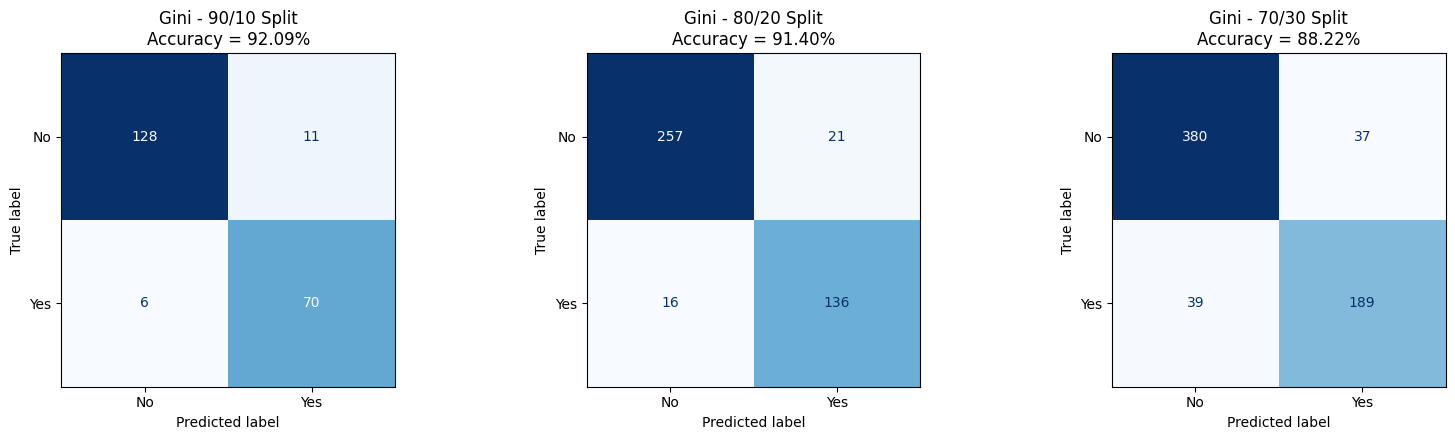

In [332]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, split in zip(axes, splits):
    name = split['name']
    disp = ConfusionMatrixDisplay(confusion_matrix=gini_results[name]['confusion_matrix'],
                                  display_labels=['No', 'Yes'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f"Gini - {name} Split\nAccuracy = {gini_results[name]['accuracy']*100:.2f}%")
plt.tight_layout()
plt.show()

## 6.2 Classification: Decision Tree with Information Gain (Entropy)

In this section, we apply **Decision Tree classification** using the Information Gain attribute selection measure (`criterion='entropy'`).

* **Input Data:** We load the finalized `Preprocessed_dataset.csv` from Phase 2, separating the selected features (X) and the target variable (Diagnosis).
* **Partitions:** We use the same three train/test splits as the Gini experiment: **90/10, 80/20, and 70/30**, so the two criteria can be compared fairly.
* **Configuration Parameters:** We use `random_state = 42` for reproducibility and `stratify = y` to keep the natural class distribution in every split. No further scaling is applied, as Decision Trees are invariant to monotonic feature scaling.

In [333]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# 1. Load the preprocessed dataset from Phase 2
df_preprocessed = pd.read_csv('Preprocessed_dataset.csv')

# 2. Define features (X) and target (y)
X = df_preprocessed.drop(columns=['Diagnosis'])
y = df_preprocessed['Diagnosis']

# Class names used in the plots (0 = No, 1 = Yes)
labels = sorted(y.unique())
class_names = ['No', 'Yes'] if labels == [0, 1] else [str(l) for l in labels]

# 3. The three partition sizes required by the project guidelines
splits = [
    {"train": 0.90, "test": 0.10, "name": "90/10"},
    {"train": 0.80, "test": 0.20, "name": "80/20"},
    {"train": 0.70, "test": 0.30, "name": "70/30"}
]

# Dictionaries to store results (used for the comparison with Gini and by Student 4)
entropy_results = {}
entropy_cms = {}
entropy_models = {}

### 6.2.1 Training and Evaluation (Entropy)

For each partition we train a Decision Tree with `criterion='entropy'`, predict the test set, then compute the accuracy and the confusion matrix.

In [334]:
for s in splits:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=s["test"], random_state=42, stratify=y
    )

    clf_entropy = DecisionTreeClassifier(criterion="entropy", random_state=42)
    clf_entropy.fit(X_train, y_train)
    y_pred = clf_entropy.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    entropy_results[s["name"]] = acc
    entropy_cms[s["name"]] = cm
    entropy_models[s["name"]] = clf_entropy

    print(f"=== Entropy | Partition {s['name']} (train/test) ===")
    print(f"Training size: {len(X_train)} | Testing size: {len(X_test)}")
    print(f"Accuracy: {acc:.4f} ({acc*100:.2f}%)")
    print("Confusion Matrix:")
    print(cm)
    print()

=== Entropy | Partition 90/10 (train/test) ===
Training size: 1934 | Testing size: 215
Accuracy: 0.9070 (90.70%)
Confusion Matrix:
[[125  14]
 [  6  70]]

=== Entropy | Partition 80/20 (train/test) ===
Training size: 1719 | Testing size: 430
Accuracy: 0.9163 (91.63%)
Confusion Matrix:
[[264  14]
 [ 22 130]]

=== Entropy | Partition 70/30 (train/test) ===
Training size: 1504 | Testing size: 645
Accuracy: 0.8977 (89.77%)
Confusion Matrix:
[[383  34]
 [ 32 196]]



### 6.2.2 Confusion Matrices (Entropy)

Rows are the actual classes and columns are the predicted classes.

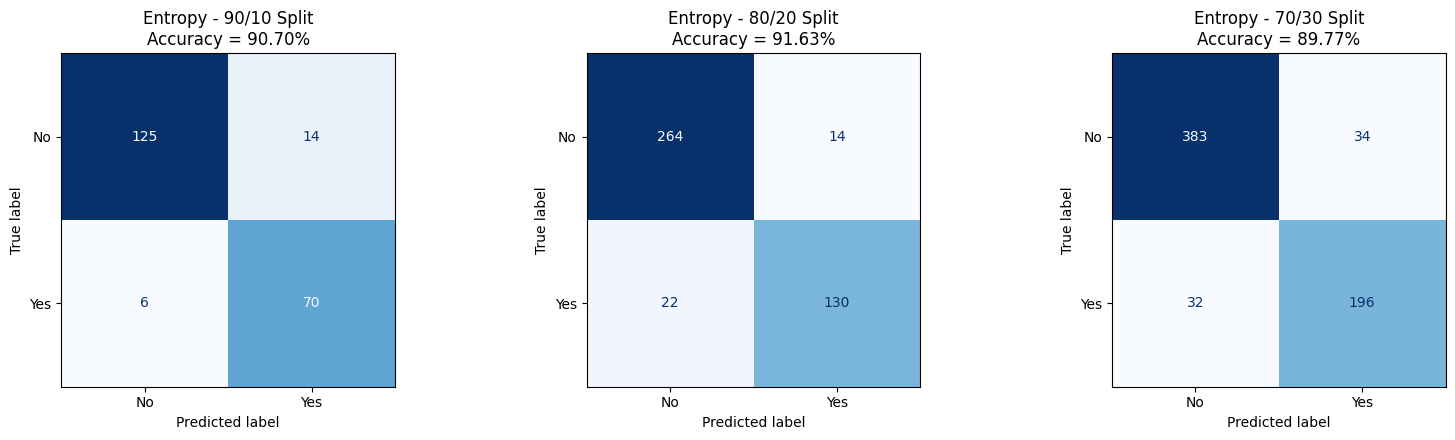

In [335]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, s in zip(axes, splits):
    disp = ConfusionMatrixDisplay(confusion_matrix=entropy_cms[s["name"]], display_labels=class_names)
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f"Entropy - {s['name']} Split\nAccuracy = {entropy_results[s['name']]*100:.2f}%")
plt.tight_layout()
plt.show()

### 6.2.3 Decision Tree Visualization (Entropy)

The tree of the 80/20 split is displayed (first 3 levels) to keep it readable. Each node shows the splitting rule, the entropy value, the number of samples, the class distribution, and the majority class.

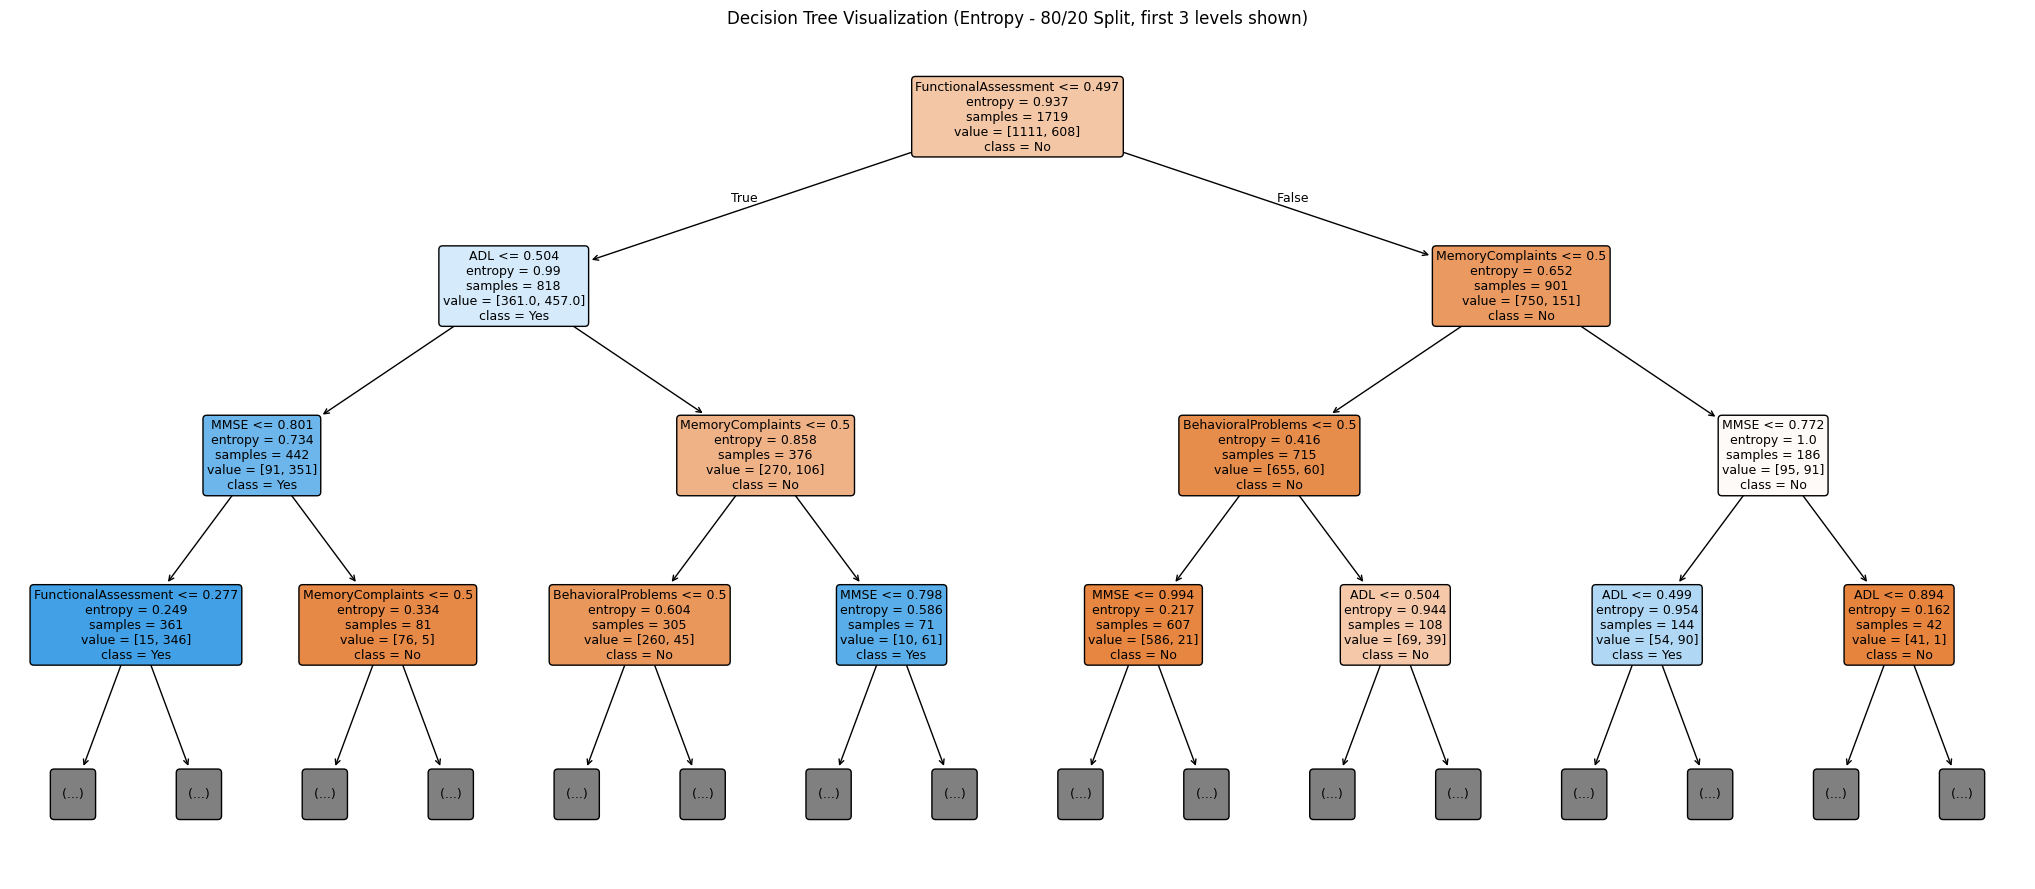

In [336]:
plt.figure(figsize=(26, 11))
plot_tree(
    entropy_models["80/20"],
    feature_names=list(X.columns),
    class_names=class_names,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.title("Decision Tree Visualization (Entropy - 80/20 Split, first 3 levels shown)")
plt.show()

### 6.2.4 Feature Importance (Entropy)

This shows which attributes contributed most to reducing entropy in the 80/20 tree.

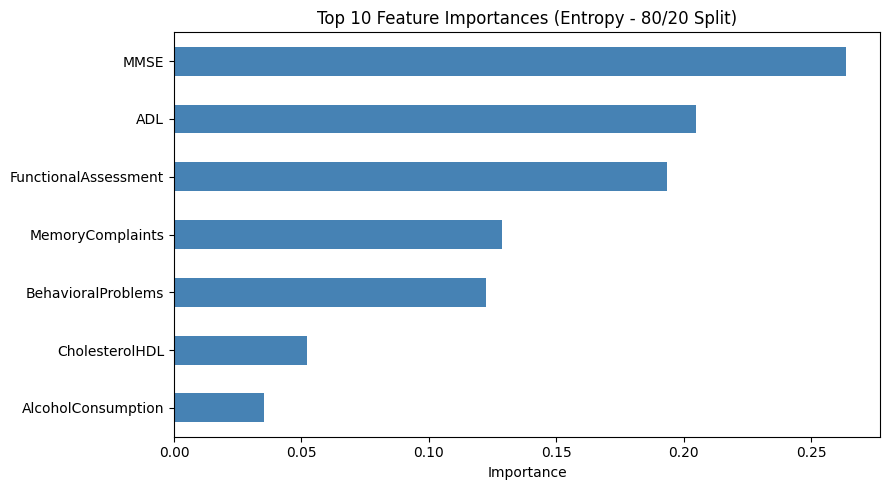

MMSE                    0.2637
ADL                     0.2047
FunctionalAssessment    0.1933
MemoryComplaints        0.1286
BehavioralProblems      0.1224
CholesterolHDL          0.0522
AlcoholConsumption      0.0351
dtype: float64


In [337]:
importances = pd.Series(entropy_models["80/20"].feature_importances_, index=X.columns)
top = importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
top[::-1].plot(kind='barh', color='steelblue')
plt.xlabel("Importance")
plt.title("Top 10 Feature Importances (Entropy - 80/20 Split)")
plt.tight_layout()
plt.show()

print(top.round(4))

### 6.2.5 Comparison: Entropy vs. Gini Index

To compare fairly, the Gini trees are re-trained here with exactly the same partitions, `random_state`, and `stratify` settings used in the Gini section.

In [338]:
gini_results = {}
gini_cms = {}

for s in splits:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=s["test"], random_state=42, stratify=y
    )
    clf_gini = DecisionTreeClassifier(criterion="gini", random_state=42)
    clf_gini.fit(X_train, y_train)
    y_pred_g = clf_gini.predict(X_test)
    gini_results[s["name"]] = accuracy_score(y_test, y_pred_g)
    gini_cms[s["name"]] = confusion_matrix(y_test, y_pred_g)

comparison = pd.DataFrame({
    "Gini Accuracy": [gini_results[s["name"]] for s in splits],
    "Entropy Accuracy": [entropy_results[s["name"]] for s in splits],
}, index=[f"{int(s['train']*100)}% train / {int(s['test']*100)}% test" for s in splits])
comparison["Difference (Entropy - Gini)"] = comparison["Entropy Accuracy"] - comparison["Gini Accuracy"]

display(comparison.style.format("{:.4f}"))

,Gini Accuracy,Entropy Accuracy,Difference (Entropy - Gini)
90% train / 10% test,0.9209,0.9070,-0.0140
80% train / 20% test,0.9140,0.9163,0.0023
70% train / 30% test,0.8822,0.8977,0.0155


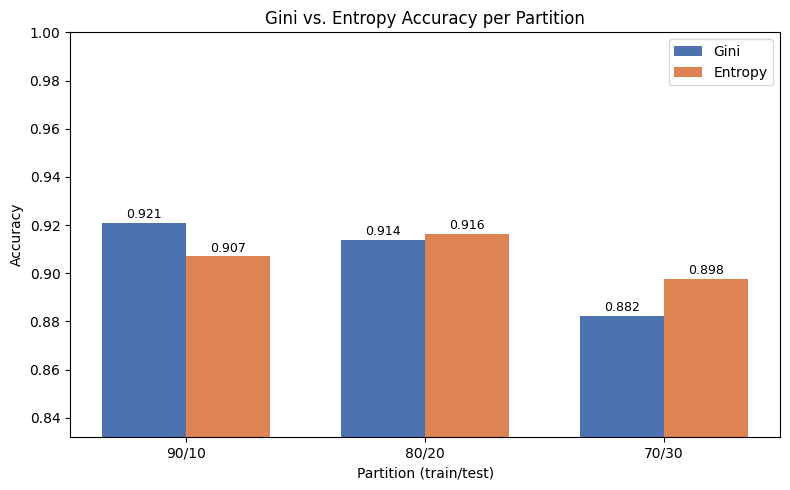

In [339]:
x = np.arange(len(splits))
w = 0.35
plt.figure(figsize=(8, 5))
b1 = plt.bar(x - w/2, comparison["Gini Accuracy"], w, label="Gini", color="#4c72b0")
b2 = plt.bar(x + w/2, comparison["Entropy Accuracy"], w, label="Entropy", color="#dd8452")
plt.xticks(x, [s["name"] for s in splits])
plt.xlabel("Partition (train/test)")
plt.ylabel("Accuracy")
lo = min(comparison["Gini Accuracy"].min(), comparison["Entropy Accuracy"].min())
plt.ylim(max(0, lo - 0.05), 1.0)
plt.title("Gini vs. Entropy Accuracy per Partition")
plt.legend()
for bars in (b1, b2):
    for b in bars:
        plt.text(b.get_x() + b.get_width()/2, b.get_height() + 0.002, f"{b.get_height():.3f}", ha='center', fontsize=9)
plt.tight_layout()
plt.show()

In [340]:
# Automatic summary of the comparison
print("Summary of the comparison:\n")
for s in splits:
    g, e = gini_results[s["name"]], entropy_results[s["name"]]
    if abs(e - g) < 1e-12:
        res = "Both criteria give the same accuracy"
    elif e > g:
        res = f"Entropy is better by {(e-g)*100:.2f} percentage points"
    else:
        res = f"Gini is better by {(g-e)*100:.2f} percentage points"
    print(f"- {s['name']}: Gini = {g:.4f}, Entropy = {e:.4f} -> {res}")

best_e = max(entropy_results, key=entropy_results.get)
best_g = max(gini_results, key=gini_results.get)
print(f"\nBest Entropy partition: {best_e} ({entropy_results[best_e]:.4f})")
print(f"Best Gini partition:    {best_g} ({gini_results[best_g]:.4f})")
print(f"Average accuracy -> Gini: {np.mean(list(gini_results.values())):.4f} | Entropy: {np.mean(list(entropy_results.values())):.4f}")

Summary of the comparison:

- 90/10: Gini = 0.9209, Entropy = 0.9070 -> Gini is better by 1.40 percentage points
- 80/20: Gini = 0.9140, Entropy = 0.9163 -> Entropy is better by 0.23 percentage points
- 70/30: Gini = 0.8822, Entropy = 0.8977 -> Entropy is better by 1.55 percentage points

Best Entropy partition: 80/20 (0.9163)
Best Gini partition:    90/10 (0.9209)
Average accuracy -> Gini: 0.9057 | Entropy: 0.9070


### Interpretation

* **Entropy (Information Gain)** chooses, at each node, the split that most reduces entropy (impurity of the class distribution). **Gini** chooses the split that most reduces the Gini impurity. Both measure how mixed the classes are in a node, so they usually select very similar splits and give close accuracies.
* The table and bar chart above show the accuracy of both criteria on each partition, and the summary cell states which one performed better on each split and on average. Any small difference comes from the different splits the two measures sometimes choose, not from one measure being fundamentally stronger.
* The confusion matrices show how the errors are distributed between the two classes (false positives vs. false negatives). For a medical diagnosis problem, false negatives (a patient with the disease predicted as healthy) are the more costly error.
* The feature-importance plot shows the attributes that the Entropy tree relied on the most, which helps explain how the classification is achieved.

## 6.3 Clustering: K-Means

In [341]:
import pandas as pd

url = "https://raw.githubusercontent.com/Wafa-Alobaidi/IT326-Data-Mining-Project/refs/heads/main/Dataset/Preprocessed_dataset.csv"

df_cluster = pd.read_csv(url)

print("Dataset shape:", df_cluster.shape)
print("Columns:", df_cluster.columns.tolist())
df_cluster.to_csv('Preprocessed_dataset.csv', index=False)

Dataset shape: (2149, 8)
Columns: ['FunctionalAssessment', 'ADL', 'MMSE', 'MemoryComplaints', 'BehavioralProblems', 'AlcoholConsumption', 'CholesterolHDL', 'Diagnosis']


In [342]:
from sklearn.preprocessing import StandardScaler

# Exclude the target column
X_cluster = df_cluster.drop(columns=['Diagnosis'])

# Standardize the features for K-Means
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

print("Clustering data shape:", X_cluster_scaled.shape)
print("Features:", X_cluster.columns.tolist())

Clustering data shape: (2149, 7)
Features: ['FunctionalAssessment', 'ADL', 'MMSE', 'MemoryComplaints', 'BehavioralProblems', 'AlcoholConsumption', 'CholesterolHDL']


### 6.3.1 Choice of K
We tested **K = 2, 3, and 4**:
- **K = 2** is the natural baseline, because the class label has two values (diagnosed / not diagnosed). It tests whether the patients split into two groups on their own.
- **K = 3 and K = 4** test whether the data contains finer subgroups, for example patients with different combinations of symptoms or different levels of functional ability.
- Larger values were not used, because with 7 features and 2,149 patients more clusters would become small and hard to interpret.

The best K is chosen using the **Silhouette coefficient** and the **Elbow method** (WCSS), shown below.

In [343]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# K values agreed upon by the team
k_values = [2, 3, 4]

# Store clustering results
kmeans_results = {}

for k in k_values:

    # Apply K-Means
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_cluster_scaled)

    # Calculate evaluation metrics
    silhouette = silhouette_score(X_cluster_scaled, cluster_labels)
    wcss = kmeans.inertia_

    # Save results for Student 4
    kmeans_results[k] = {
        'silhouette': silhouette,
        'wcss': wcss,
        'labels': cluster_labels
    }

    print(f"K = {k}")
    print(f"Silhouette Score: {silhouette:.4f}")
    print(f"WCSS: {wcss:.4f}")
    print("-----------------------")

K = 2
Silhouette Score: 0.2341
WCSS: 12885.3427
-----------------------
K = 3
Silhouette Score: 0.2284
WCSS: 11054.0390
-----------------------
K = 4
Silhouette Score: 0.1648
WCSS: 9915.1536
-----------------------


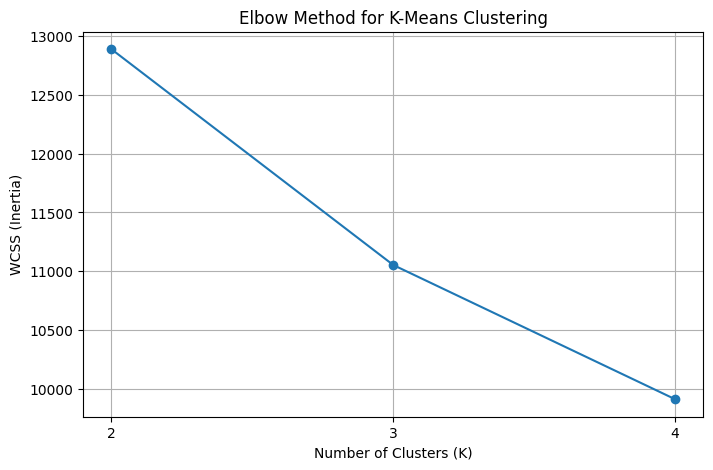

In [344]:
import matplotlib.pyplot as plt

# Extract WCSS values
wcss_values = [kmeans_results[k]['wcss'] for k in k_values]

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss_values, marker='o')

plt.title('Elbow Method for K-Means Clustering')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(k_values)
plt.grid(True)
plt.show()

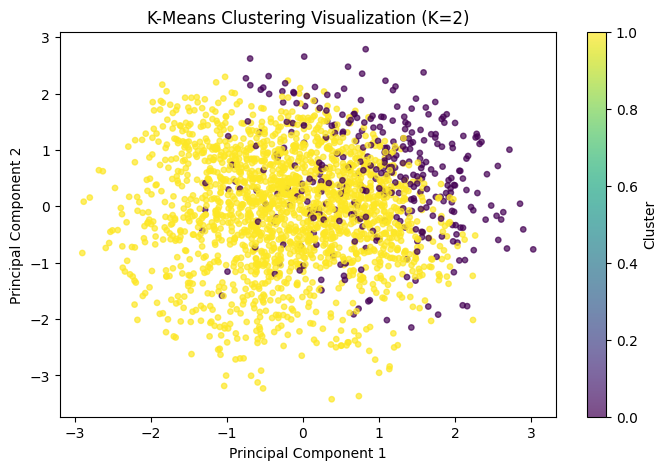

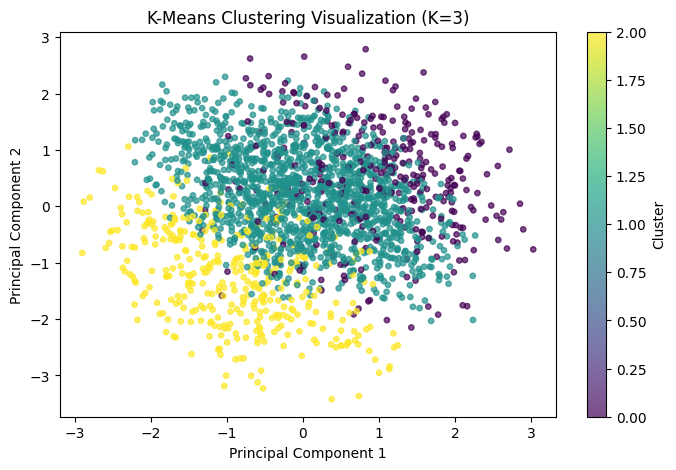

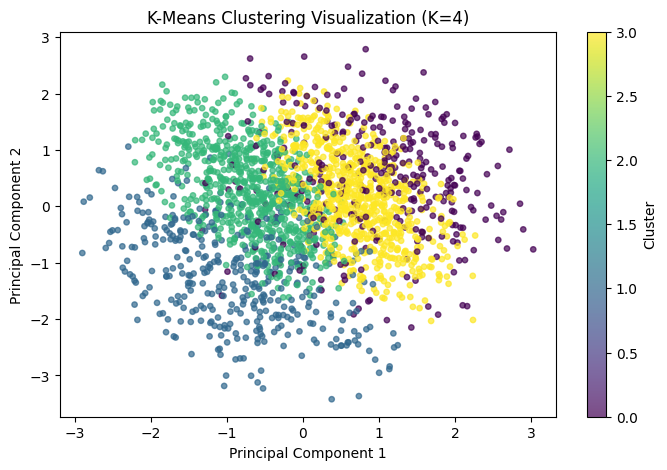

In [345]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce dimensions to 2D for visualization only
pca = PCA(n_components=2)
X_cluster_2d = pca.fit_transform(X_cluster_scaled)

# Visualize clusters for each K
for k in k_values:
    labels = kmeans_results[k]['labels']

    plt.figure(figsize=(8, 5))

    scatter = plt.scatter(
        X_cluster_2d[:, 0],
        X_cluster_2d[:, 1],
        c=labels,
        cmap='viridis',
        s=15,
        alpha=0.7
    )

    plt.title(f'K-Means Clustering Visualization (K={k})')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.colorbar(scatter, label='Cluster')
    plt.show()

In [346]:
# Analyze cluster characteristics for all K values

for k in k_values:
    print(f"\n========== K = {k} ==========")

    cluster_analysis = X_cluster.copy()
    cluster_analysis['Cluster'] = kmeans_results[k]['labels']

    # Calculate feature averages for each cluster
    cluster_summary = cluster_analysis.groupby('Cluster').mean()

    print("Average feature values for each cluster:")
    display(cluster_summary.round(3))

    # Show the number of records in each cluster
    print("Number of records in each cluster:")
    print(cluster_analysis['Cluster'].value_counts().sort_index())


========== K = 2 ==========
Average feature values for each cluster:


,FunctionalAssessment,ADL,MMSE,MemoryComplaints,BehavioralProblems,AlcoholConsumption,CholesterolHDL
Cluster,,,,,,,
0,0.493,0.528,0.509,0.199,1.0,0.511,0.512
1,0.511,0.493,0.489,0.210,0.0,0.500,0.490


Number of records in each cluster:
Cluster
0     337
1    1812
Name: count, dtype: int64

========== K = 3 ==========
Average feature values for each cluster:


,FunctionalAssessment,ADL,MMSE,MemoryComplaints,BehavioralProblems,AlcoholConsumption,CholesterolHDL
Cluster,,,,,,,
0,0.493,0.528,0.509,0.199,1.0,0.511,0.512
1,0.512,0.500,0.488,0.000,0.0,0.507,0.487
2,0.508,0.466,0.490,1.000,0.0,0.476,0.503


Number of records in each cluster:
Cluster
0     337
1    1432
2     380
Name: count, dtype: int64

========== K = 4 ==========
Average feature values for each cluster:


,FunctionalAssessment,ADL,MMSE,MemoryComplaints,BehavioralProblems,AlcoholConsumption,CholesterolHDL
Cluster,,,,,,,
0,0.493,0.528,0.509,0.199,1.0,0.511,0.512
1,0.508,0.466,0.490,1.000,0.0,0.476,0.503
2,0.449,0.242,0.483,0.000,0.0,0.500,0.498
3,0.573,0.752,0.494,0.000,0.0,0.513,0.476


Number of records in each cluster:
Cluster
0    337
1    380
2    707
3    725
Name: count, dtype: int64


### K-Means Clustering Results and Interpretation

K-Means was applied using K = 2, 3, and 4 to examine different clustering configurations. All seven selected features were used, excluding Diagnosis.

**K = 2:** The data was divided into two clusters (337 and 1812 records), mainly distinguished by BehavioralProblems. This configuration achieved the highest Silhouette Score (0.2341), indicating the best relative separation among the tested values.

**K = 3:** Three clusters were formed (337, 1432, and 380 records), distinguished mainly by BehavioralProblems and MemoryComplaints. The Silhouette Score was 0.2284, showing performance close to K = 2 with more detailed grouping.

**K = 4:** Four clusters were formed (337, 380, 707, and 725 records). The groups were distinguished by BehavioralProblems, MemoryComplaints, and ADL. The Silhouette Score decreased to 0.1648, indicating weaker separation.

**Overall Interpretation:** WCSS decreased as K increased, but the Elbow Method did not show a clear optimal K among the tested values. Meanwhile, K = 2 achieved the highest Silhouette Score. The relatively low scores and visible overlap suggest limited cluster separation.

PCA was used only for two-dimensional visualization, while clustering was performed using all seven selected features.


## 6.4 Comparison of Results

This section compares the performance of the Decision Tree classification models using Gini Index and Entropy across three training/testing partitions (90/10, 80/20, and 70/30). It also compares the K-Means clustering results for K = 2, 3, and 4 using Silhouette Scores and Within-Cluster Sum of Squares (WCSS) to identify the best-performing configurations.

In [347]:
# Classification comparison table

classification_comparison = pd.DataFrame({
    'Train/Test Split': ['90/10', '80/20', '70/30'],
    'Gini Accuracy': [
        gini_results['90/10'],
        gini_results['80/20'],
        gini_results['70/30']
    ],
    'Entropy Accuracy': [
        entropy_results['90/10'],
        entropy_results['80/20'],
        entropy_results['70/30']
    ]
})

display(classification_comparison.round(4))

,Train/Test Split,Gini Accuracy,Entropy Accuracy
0,90/10,0.9209,0.9070
1,80/20,0.9140,0.9163
2,70/30,0.8822,0.8977


### Classification Results and Interpretation

We compared the Decision Tree results using Gini Index and Entropy with three different train/test splits: 90/10, 80/20, and 70/30.

For the 90/10 split, Gini had a higher accuracy of 92.09%, while Entropy achieved 90.70%. For the 80/20 split, Entropy performed slightly better with 91.63%, compared to 91.40% for Gini. For the 70/30 split, Entropy also had a higher accuracy of 89.77%, while Gini achieved 88.22%.

From these results, Gini with the 90/10 split gave us the highest accuracy overall at 92.09%. However, this split uses a smaller testing set, so we cannot be sure it would always perform better on other data.

In [348]:
# K-Means clustering comparison table

clustering_comparison = pd.DataFrame({
    'K': [2, 3, 4],
    'Silhouette Score': [
        kmeans_results[k]['silhouette'] for k in [2, 3, 4]
    ],
    'WCSS': [
        kmeans_results[k]['wcss'] for k in [2, 3, 4]
    ]
})

display(clustering_comparison.round(4))

,K,Silhouette Score,WCSS
0,2,0.2341,12885.3427
1,3,0.2284,11054.0390
2,4,0.1648,9915.1536


### Clustering Results and Interpretation

We compared the K-Means clustering results using K = 2, 3, and 4. To evaluate the clusters, we used the Silhouette Score and the Elbow Method (WCSS).

K = 2 had the highest Silhouette Score of 0.2341, followed by K = 3 with 0.2284 and K = 4 with 0.1648. This means K = 2 gave the best separation between clusters out of the three values we tested.

The WCSS decreased as K increased. It was 12885.3427 for K = 2, 11054.0390 for K = 3, and 9915.1536 for K = 4. This is expected because increasing the number of clusters usually reduces WCSS.

The Elbow Method suggests that K = 3 might be a good choice, but the elbow is not very clear from the three values we tested. Since the Silhouette Score supports K = 2 while the Elbow Method suggests K = 3, we could not confirm a clear majority agreement between the two methods.

We selected K = 2 because it had the highest Silhouette Score. However, the scores were relatively low, which means the clusters were not strongly separated.

# [7] Findings and Discussion

This section explains what the results mean for our problem: predicting Alzheimer's disease and finding groups of similar patients. All numbers come from the experiments in Section [6].

## 7.1 Classification Findings

**Best model.** All six decision trees reached between **88.22% and 92.09%** accuracy, so the routine patient measurements carry strong information about the diagnosis. The best result is the **Gini index tree with the 90/10 partition (92.09%)**, which we use as our final classification model. On average the two measures are almost equal (Gini 90.57%, Entropy 90.70%): Gini was better on 90/10, while Entropy was slightly better on 80/20 and 70/30. This is expected, because both Gini and entropy measure how mixed the classes are in a node, so they usually choose very similar splits.

**Effect of partition size.** For both measures, accuracy is highest with the most training data (90/10) and lowest with 70/30, because a larger training set gives the tree more examples to learn from. However, the 90/10 test set has only 215 patients, so each misclassified patient changes the accuracy by about 0.5 percentage points. The 80/20 results (about 91.4–91.6% for both measures, on 430 test patients) are therefore the most reliable estimate for new patients.

**Errors.** In a medical problem, a **false negative** (a patient with Alzheimer's predicted as healthy) is the more costly error, because the patient could miss early care. The final Gini 90/10 model missed only 6 of the 76 diagnosed patients in its test set, and it made 11 false positives.

The cells below re-create the final model with exactly the same settings as Section 6.1, show its first levels, and convert its split values back to the original units.

Final model: Decision Tree (Gini index), 90/10 partition
Test accuracy:      0.9209
Training accuracy:  1.0000
Recall (AD class):  0.9211
Precision (AD):     0.8642
Tree depth: 19 | Number of leaves: 154


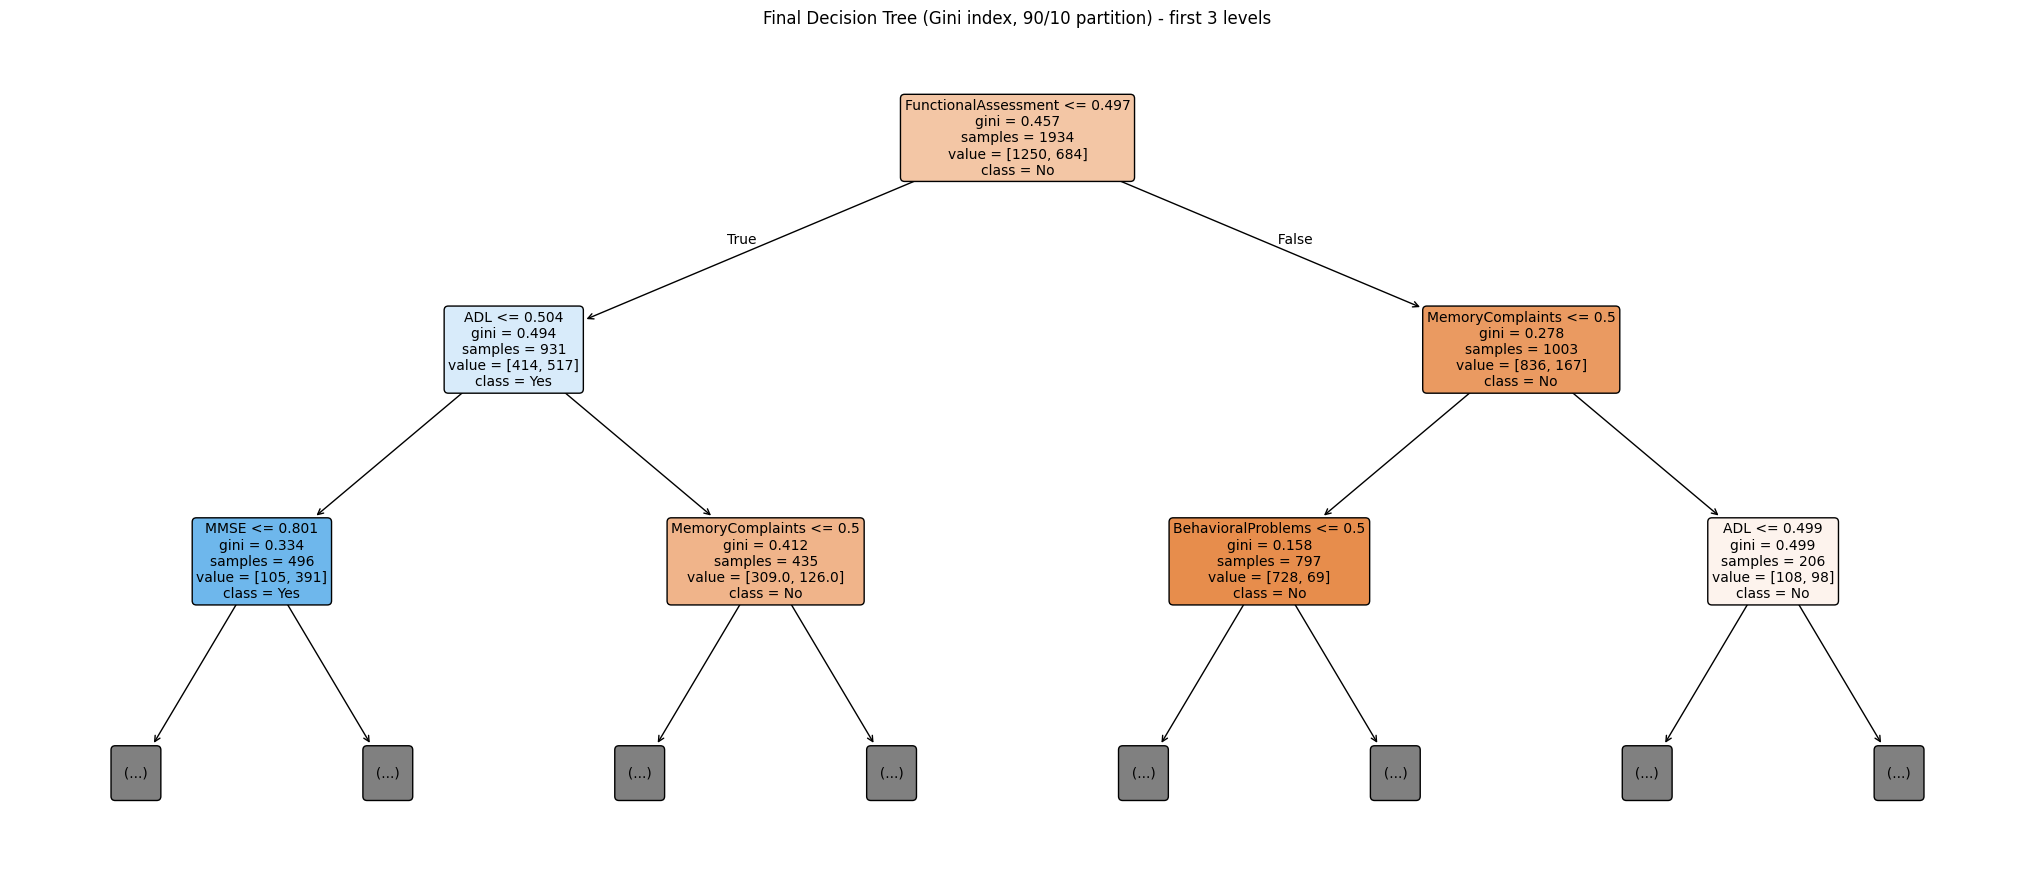

In [349]:
from sklearn.metrics import recall_score, precision_score

# Final model: Gini index, 90/10 partition (same settings as Section 6.1)
X_tr_f, X_te_f, y_tr_f, y_te_f = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)
final_tree = DecisionTreeClassifier(criterion='gini', random_state=42)
final_tree.fit(X_tr_f, y_tr_f)
y_pred_f = final_tree.predict(X_te_f)

print("Final model: Decision Tree (Gini index), 90/10 partition")
print(f"Test accuracy:      {accuracy_score(y_te_f, y_pred_f):.4f}")
print(f"Training accuracy:  {final_tree.score(X_tr_f, y_tr_f):.4f}")
print(f"Recall (AD class):  {recall_score(y_te_f, y_pred_f):.4f}")
print(f"Precision (AD):     {precision_score(y_te_f, y_pred_f):.4f}")
print(f"Tree depth: {final_tree.get_depth()} | Number of leaves: {final_tree.get_n_leaves()}")

plt.figure(figsize=(26, 11))
plot_tree(final_tree, feature_names=list(X.columns), class_names=['No', 'Yes'],
          filled=True, rounded=True, max_depth=2, fontsize=10)
plt.title("Final Decision Tree (Gini index, 90/10 partition) - first 3 levels")
plt.show()

In [350]:
# Convert the top split values from the normalized [0, 1] scale back to the original units.
# Min-Max normalization: normalized = (value - min) / (max - min)  =>  value = min + normalized * (max - min)
raw_df = pd.read_csv('https://raw.githubusercontent.com/Wafa-Alobaidi/IT326-Data-Mining-Project/refs/heads/main/Dataset/Raw_dataset.csv')
continuous_features = ['FunctionalAssessment', 'ADL', 'MMSE', 'AlcoholConsumption', 'CholesterolHDL']

tree_ = final_tree.tree_
def describe_node(node, depth=0, max_depth=2):
    if depth > max_depth or tree_.children_left[node] == -1:
        return
    feature = X.columns[tree_.feature[node]]
    t = tree_.threshold[node]
    if feature in continuous_features:
        original = raw_df[feature].min() + t * (raw_df[feature].max() - raw_df[feature].min())
        rule = f"{feature} <= {t:.2f} (normalized)  =  {feature} <= {original:.1f} (original units)"
    else:
        rule = f"{feature} = 0 (No) vs. 1 (Yes)"
    print("    " * depth + f"Level {depth + 1}: {rule}   [{int(tree_.n_node_samples[node])} patients]")
    describe_node(tree_.children_left[node], depth + 1, max_depth)
    describe_node(tree_.children_right[node], depth + 1, max_depth)

describe_node(0)

Level 1: FunctionalAssessment <= 0.50 (normalized)  =  FunctionalAssessment <= 5.0 (original units)   [1934 patients]
    Level 2: ADL <= 0.50 (normalized)  =  ADL <= 5.0 (original units)   [931 patients]
        Level 3: MMSE <= 0.80 (normalized)  =  MMSE <= 24.0 (original units)   [496 patients]
        Level 3: MemoryComplaints = 0 (No) vs. 1 (Yes)   [435 patients]
    Level 2: MemoryComplaints = 0 (No) vs. 1 (Yes)   [1003 patients]
        Level 3: BehavioralProblems = 0 (No) vs. 1 (Yes)   [797 patients]
        Level 3: ADL <= 0.50 (normalized)  =  ADL <= 5.0 (original units)   [206 patients]


**What the final tree reveals.**
- The **first split is FunctionalAssessment ≤ 5.0** (on its original 0–10 scale). The first question the tree asks is whether the patient's functional ability is low or high. Patients with low functional scores are much more likely to be diagnosed.
- The next splits use **ADL ≤ 5.0** (Activities of Daily Living, 0–10), **MemoryComplaints**, **BehavioralProblems**, and **MMSE**. The MMSE split is at about **24 points** (out of 30). This is close to the cut-off commonly used in clinical screening, where a score below about 24 suggests cognitive impairment [8], so the tree learned a rule that matches medical practice.
- The feature importances (Section 6.2.4) confirm the same five attributes: **MMSE, ADL, FunctionalAssessment, MemoryComplaints, and BehavioralProblems** make almost all of the tree's decisions, while AlcoholConsumption and CholesterolHDL contribute very little. This also confirms our Phase 2 feature selection.

**Problem solution (classification).** Patients with low functional assessment and ADL scores, a low MMSE score, and reported memory complaints or behavioral problems should be prioritized for Alzheimer's screening. Cognitive and functional assessments are the most useful measurements.

**Limitation.** The trees were grown with the default settings (no depth limit), so they reach about 19–23 levels and 100% training accuracy. The gap between training accuracy (100%) and test accuracy (88–92%) shows some overfitting. Limiting the tree depth (pruning) would give a smaller tree that is easier to read and might generalize better. We kept the default settings agreed by the team so that all six configurations can be compared directly.

## 7.2 Clustering Findings

**Best K.** K = 2 has the highest average Silhouette width (0.2341), slightly above K = 3 (0.2284), while K = 4 is clearly lower (0.1648). In the Elbow plot, WCSS decreases as K increases, with a slightly larger drop from K = 2 to 3 (−14.2%) than from 3 to 4 (−10.3%), but there is no sharp elbow. Because the Silhouette coefficient gives a clear answer and the Elbow method does not, **K = 2** is selected as the optimal number of clusters, as concluded in Section 6.4.

**How good are the clusters?** All Silhouette values are low (below 0.25), so the clusters overlap and are not strongly separated, which is also visible in the PCA plots. The cluster profiles in Section 6.3 explain why: the clusters are formed mainly by the **binary attributes**. With K = 2, cluster 0 is exactly the 337 patients with BehavioralProblems = 1. K = 3 also separates patients with MemoryComplaints = 1, and K = 4 further divides the remaining patients by their ADL score. The continuous attributes are spread almost uniformly (Section 3.4.1), so they do not form natural groups.

The cells below compare the clusters with the **Diagnosis label**, which was **not** used for clustering, to check whether the groups are meaningful for our problem.

K = 2


,Not diagnosed (0),Diagnosed (1),Patients,% diagnosed
Cluster,,,,
0,134,203,337,60.2
1,1255,557,1812,30.7


K = 3


,Not diagnosed (0),Diagnosed (1),Patients,% diagnosed
Cluster,,,,
0,134,203,337,60.2
1,1105,327,1432,22.8
2,150,230,380,60.5


K = 4


,Not diagnosed (0),Diagnosed (1),Patients,% diagnosed
Cluster,,,,
0,134,203,337,60.2
1,150,230,380,60.5
2,406,301,707,42.6
3,699,26,725,3.6


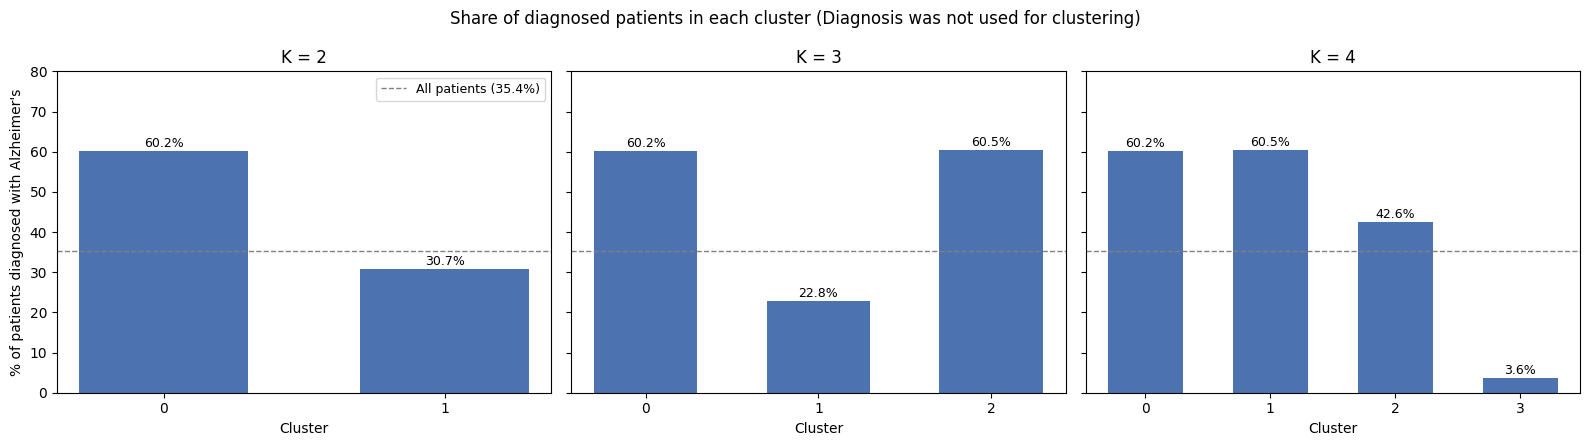

In [351]:
# Proportion of diagnosed patients (Diagnosis = 1) in each cluster, for every K
overall_rate = df_cluster['Diagnosis'].mean() * 100
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, k in zip(axes, k_values):
    table = pd.crosstab(kmeans_results[k]['labels'], df_cluster['Diagnosis'])
    table.index.name = 'Cluster'
    table.columns = ['Not diagnosed (0)', 'Diagnosed (1)']
    table['Patients'] = table.sum(axis=1)
    table['% diagnosed'] = (table['Diagnosed (1)'] / table['Patients'] * 100).round(1)
    print(f"K = {k}")
    display(table)

    bars = ax.bar(table.index.astype(str), table['% diagnosed'], color='#4c72b0', width=0.6)
    ax.axhline(overall_rate, color='gray', linestyle='--', linewidth=1, label=f"All patients ({overall_rate:.1f}%)")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{b.get_height():.1f}%", ha='center', fontsize=9)
    ax.set_title(f"K = {k}")
    ax.set_xlabel("Cluster")
axes[0].set_ylabel("% of patients diagnosed with Alzheimer's")
axes[0].set_ylim(0, 80)
axes[0].legend(loc='upper right', fontsize=9)
fig.suptitle("Share of diagnosed patients in each cluster (Diagnosis was not used for clustering)")
plt.tight_layout()
plt.show()

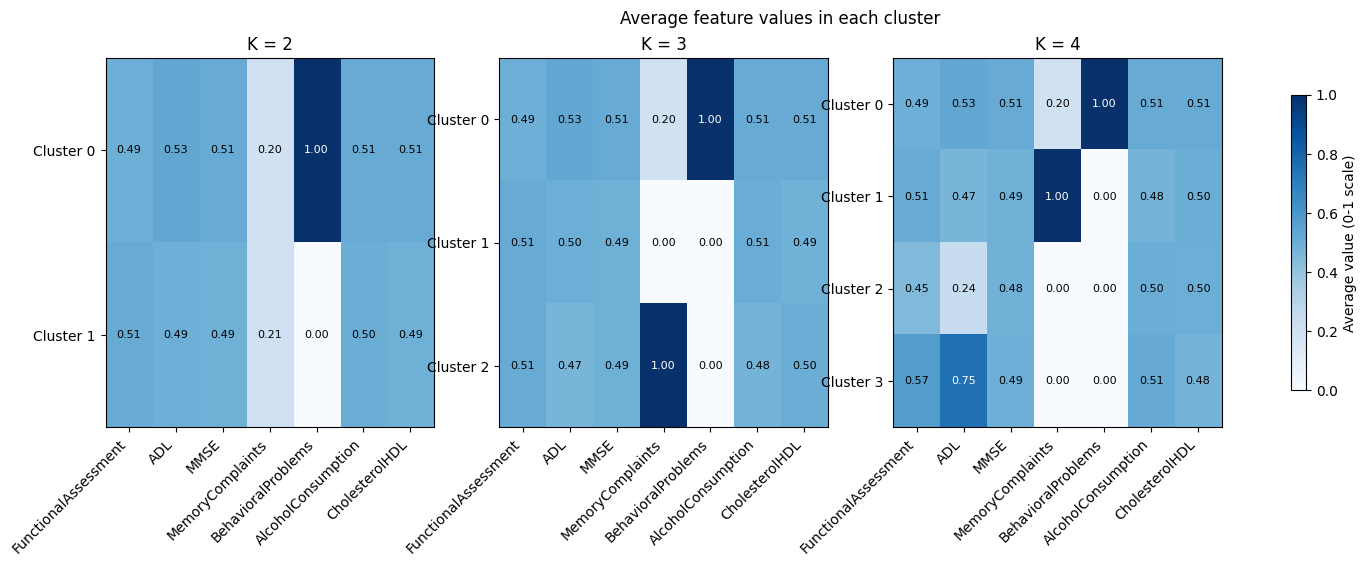

In [352]:
# Cluster profiles: average value of each feature per cluster (all features are on a 0-1 scale)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, k in zip(axes, k_values):
    profile = X_cluster.copy()
    profile['Cluster'] = kmeans_results[k]['labels']
    means = profile.groupby('Cluster').mean()
    im = ax.imshow(means.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(means.columns)))
    ax.set_xticklabels(means.columns, rotation=45, ha='right')
    ax.set_yticks(range(k))
    ax.set_yticklabels([f"Cluster {c}" for c in means.index])
    for r in range(means.shape[0]):
        for c in range(means.shape[1]):
            v = means.values[r, c]
            ax.text(c, r, f"{v:.2f}", ha='center', va='center', fontsize=8, color='white' if v > 0.6 else 'black')
    ax.set_title(f"K = {k}")
fig.colorbar(im, ax=axes, shrink=0.8, label='Average value (0-1 scale)')
fig.suptitle("Average feature values in each cluster")
plt.show()

**Are the clusters meaningful?** Yes, even though they are not well separated. Overall, 35.4% of patients are diagnosed, but the share differs strongly between clusters:
- **K = 2:** the cluster of patients with behavioral problems has **60.2%** diagnosed patients, compared with **30.7%** in the other cluster.
- **K = 3:** the behavioral-problems cluster (60.2%) and the memory-complaints cluster (60.5%) are both high-risk groups, while patients with neither symptom have only **22.8%** diagnosed.
- **K = 4:** the most interesting result. Among patients with neither symptom, K-means splits them by ADL. The group with **high ADL scores** (average 0.75 on the normalized scale) has only **3.6%** diagnosed patients (26 of 725), while the group with **low ADL scores** (average 0.24) has **42.6%**.

**Problem solution (clustering).** Without seeing the diagnosis, K-means found patient groups whose rate of Alzheimer's ranges from about 4% to about 60%. Patients who report memory complaints or show behavioral problems form high-risk groups, and patients who are independent in daily activities form a very low-risk group. K = 2 is the best K by the Silhouette coefficient, but K = 4 gives the most useful clinical picture, because it separates a clear low-risk group.

**Limitation.** After standardization, the binary attributes (0 or 1) create large distances, so they dominate the Euclidean distance and the clusters mainly reproduce the symptom attributes. The low Silhouette values show that the patients form a continuum rather than clearly separated groups.

## 7.3 Comparison with the Research Paper

We compare our results with Dubey et al. [1], who used the **same Kaggle dataset**:

- **Feature selection:** Dubey et al. used K-Best (Chi-square and ANOVA F-value) and kept the top 5 features: FunctionalAssessment, MMSE, ADL, MemoryComplaints, and BehavioralProblems. We used mutual information (threshold 0.01) and kept 7 features: the same 5, plus AlcoholConsumption and CholesterolHDL.
- **Class imbalance:** Dubey et al. randomly removed majority-class patients to get a balanced dataset (760 / 760). We kept all 2,149 patients (64.6% / 35.4%) and used stratified train/test splits.
- **Models:** Dubey et al. used ensemble models (Random Forest, Gradient Boosting, XGBoost, AdaBoost, and Histogram Gradient Boosting). We used a single Decision Tree with Gini and entropy.
- **Best accuracy:** Dubey et al. reached **95.18%** with Gradient Boosting (Random Forest 94.96%, AdaBoost 91.67%). Our best result is **92.09%** (Gini, 90/10), with 88.22–92.09% across all 6 configurations.
- **Clustering:** Dubey et al. did not apply clustering. We applied K-means with K = 2, 3, and 4.

**Discussion.**
- **Same important features.** Both studies found that the cognitive and functional measures (FunctionalAssessment, MMSE, ADL) and the symptoms MemoryComplaints and BehavioralProblems are the strongest predictors. Our final tree uses exactly these attributes at its top levels, so our results agree with the paper.
- **Accuracy.** Our single decision tree is about 3 percentage points below the paper's best model. This is expected, because ensemble methods such as Gradient Boosting and Random Forest combine many trees, which reduces the overfitting we observed in a single fully grown tree. Our best result is close to the paper's AdaBoost (91.67%), using a much simpler model that can be read and drawn.
- **Different balancing choice.** The paper balanced the classes by removing majority-class records, so its accuracy is measured on a 50/50 test set. We kept all 2,149 patients and used stratified splits, so our test sets keep the real 65/35 distribution. The two accuracy values are therefore not measured under exactly the same conditions.
- **Our addition.** The paper did not apply clustering. Our K-means results add a new finding: patient groups based on symptoms and daily-living ability differ greatly in their rate of Alzheimer's (about 4% to 60%), even though the clustering never saw the diagnosis.

## 7.4 Conclusion

- **Best classification model:** Decision Tree with the **Gini index on the 90/10 partition (92.09% accuracy, recall ≈ 92% for the Alzheimer's class)**. Both measures performed similarly (average 90.57% for Gini vs. 90.70% for entropy), and the most informative attributes were FunctionalAssessment, ADL, MMSE, MemoryComplaints, and BehavioralProblems.
- **Best clustering:** **K = 2** by the Silhouette coefficient (0.2341). The clusters overlap, but they are strongly related to the diagnosis, and K = 4 reveals a very low-risk group of patients who are independent in daily activities (3.6% diagnosed).
- **Answer to our problem:** Routine cognitive and functional assessments, together with reported memory complaints and behavioral problems, are enough to identify most patients with Alzheimer's disease using simple, readable rules, and to divide patients into groups with very different levels of risk.
- **Future work:** pruning the decision tree to reduce overfitting, reporting precision, recall, and F1 for every configuration, and trying ensemble methods as in [1].

# [8] References

[1] Y. Dubey, A. Bhongade, P. Palsodkar, and P. Fulzele, "Efficient explainable models for Alzheimer's disease classification with feature selection and data balancing approach using ensemble learning," *Diagnostics*, vol. 14, no. 24, Art. no. 2770, Dec. 2024, doi: 10.3390/diagnostics14242770.

[2] R. El Kharoua, "Alzheimer's disease dataset," Kaggle, 2024. [Online]. Available: https://www.kaggle.com/datasets/rabieelkharoua/alzheimers-disease-dataset

[3] L. Breiman, J. H. Friedman, R. A. Olshen, and C. J. Stone, *Classification and Regression Trees*. Belmont, CA, USA: Wadsworth, 1984.

[4] J. R. Quinlan, "Induction of decision trees," *Machine Learning*, vol. 1, no. 1, pp. 81–106, 1986, doi: 10.1007/BF00116251.

[5] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[6] S. P. Lloyd, "Least squares quantization in PCM," *IEEE Transactions on Information Theory*, vol. 28, no. 2, pp. 129–137, Mar. 1982, doi: 10.1109/TIT.1982.1056489.

[7] P. J. Rousseeuw, "Silhouettes: A graphical aid to the interpretation and validation of cluster analysis," *Journal of Computational and Applied Mathematics*, vol. 20, pp. 53–65, 1987, doi: 10.1016/0377-0427(87)90125-7.

[8] T. N. Tombaugh and N. J. McIntyre, "The mini-mental state examination: A comprehensive review," *Journal of the American Geriatrics Society*, vol. 40, no. 9, pp. 922–935, 1992, doi: 10.1111/j.1532-5415.1992.tb01992.x.